In [1]:
# standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica'],  # Use Helvetica
    'font.size': 8,                    # Global font size
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'figure.titlesize': 8,
    'pdf.fonttype': 42,                # Embed fonts in PDFs for Illustrator
    'ps.fonttype': 42
})
#import pygmt
from pyproj import Proj, Geod
from osgeo import gdal
import geopandas as gpd
import pygmt
import rioxarray
import rasterio

import sys
sys.path.append('/Users/chanagan/Documents/GitHub/ImageryResources/Functions/')
import TiffTools as tt

# reload modules when changed
%reload_ext autoreload
%autoreload 2

## Introductory figure components

In [21]:
whole_region = [-68.7206,-66.5569,10.3367,10.7673]
west_region = [-68.27839,-68.13129,10.48393,10.57463]
laguaira = [-67.058411,-66.956876,10.593025,10.620872]
caraballeda = [-66.864813,-66.833277,10.612358, 10.623077]
naiguata = [-66.749153,-66.732331, 10.618626,10.626109]
camuri = [-66.720998,-66.709055,10.621482,10.627419]
naiguata_camuri = [-66.749153,-66.709055, 10.618626,10.627419]

simple_trace = gpd.read_file('/Volumes/Venezuela/Venezuela2026Doublet/GIS/SimpleTraceEPSG4326.geojson')

grid = pygmt.datasets.load_earth_relief(
    resolution='03s',
    region=whole_region,
    use_srtm=True)

dgrid = pygmt.grdgradient(grid=grid, radiance=[315, 60])
crs = 'epsg:32619'
P = Proj(crs)
G = Geod(ellps='WGS84')

gdf = gpd.read_file('/Volumes/Venezuela/Venezuela2026Doublet/GIS/gem_active_faults_harmonized.geojson',driver="GeoJSON")

cities = {
    "Caracas": (-66.9036, 10.4806),
    "Puerto Cabello": (-68.0125, 10.4731),
    "Morón": (-68.2003, 10.4881),
}
city_df = pd.DataFrame(
    {
        "city": cities.keys(),
        "lon": [v[0] for v in cities.values()],
        "lat": [v[1] for v in cities.values()],
    }
)

s2ew_file = '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_20260505_20260629_EW_masked.tif'
im = rioxarray.open_rasterio(s2ew_file)
im = im.rio.reproject("EPSG:4326")

s2im_file = '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/PREsentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif'
imS2 = rioxarray.open_rasterio(s2im_file)
imS2 = imS2.rio.reproject("EPSG:4326")

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GeoJSON does not support open option DRIVER
  return ogr_read(


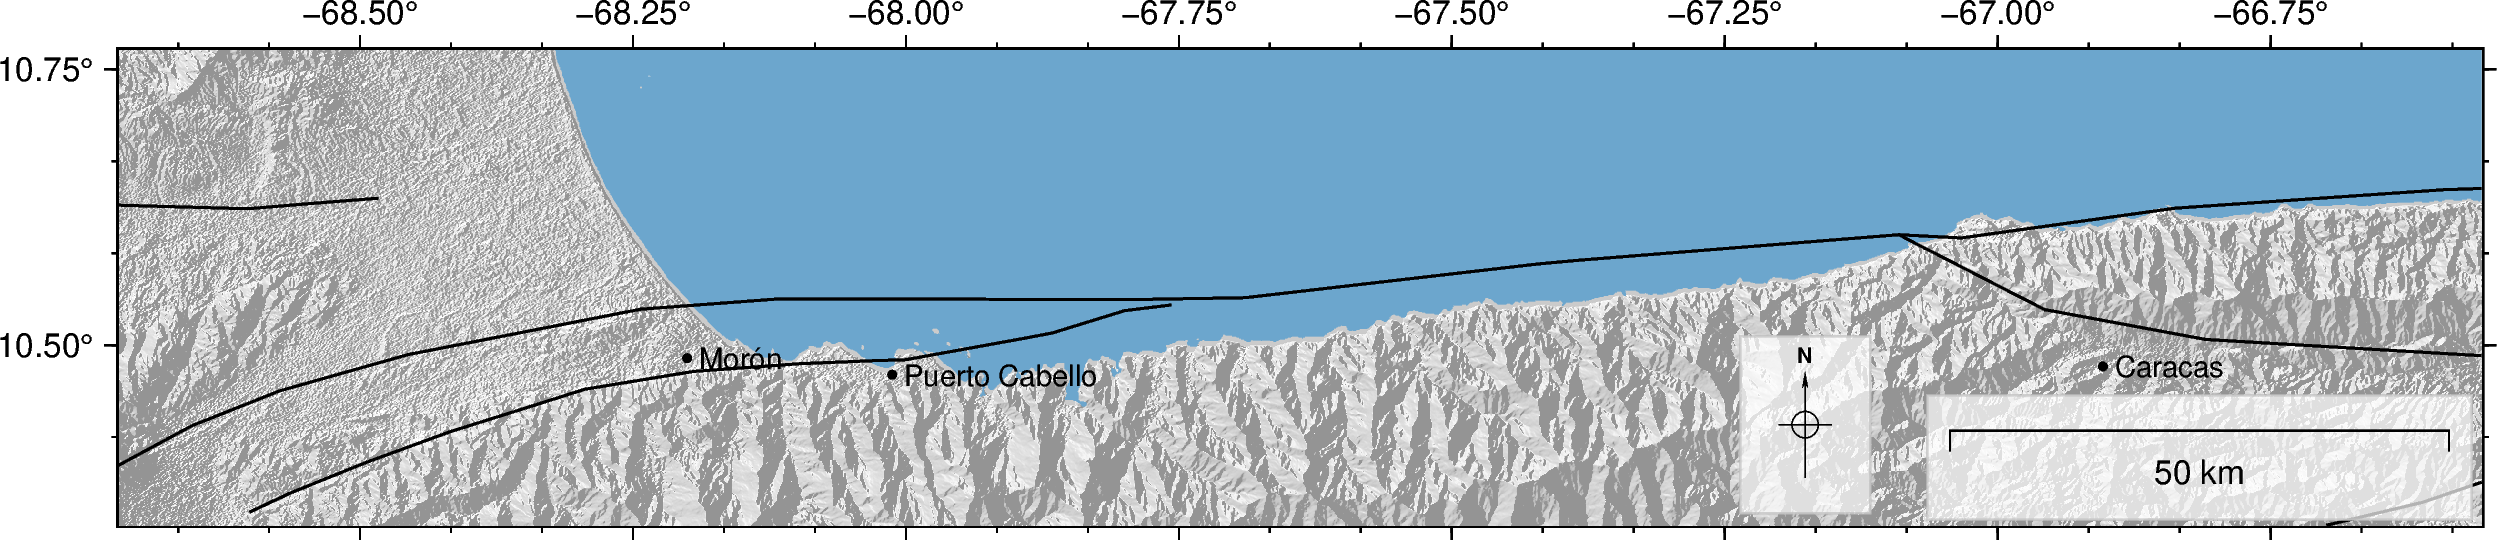

In [22]:
# Introductory figure base
fig = pygmt.Figure()

# Configuration for the 'current figure'.
pygmt.config(MAP_FRAME_TYPE="plain")
pygmt.config(FORMAT_GEO_MAP="ddd.xx")
pygmt.config(FONT_ANNOT_PRIMARY="8p")
pygmt.config(FONT_ANNOT_SECONDARY="6p")

# Plot the base map of the main figure. 
fig.basemap(region=whole_region, projection="M20c", frame=["WNse", "af"])

# Hillshade
pygmt.makecpt(cmap="gray", series=[-2.7, 0.3, 0.01],transparency=60)
fig.grdimage(grid=dgrid, cmap=True)

# Plot a rectangle ("r") in the inset map to show the area of the main
# figure. "+s" means that the first two columns are the longitude and
# latitude of the bottom left corner of the rectangle, and the last two
# columns the longitude and latitude of the upper right corner.
fig.coast(water='skyblue3')
fig.plot(data=gdf, pen="0.6p,black")#,connection="r")
fig.plot(x=city_df.lon,y=city_df.lat,style="c0.08c",fill='black')
fig.text(x=city_df.lon,y=city_df.lat,text=city_df.city,font="7p,Helvetica,black",justify="LM",offset="0.10c/0c")


fig.basemap(map_scale='JBR+w50k+o-4.5c/-0.8c+lkm',box="+c0.1/0.3+gwhite@30+p0.5p,grey@30,solid",rose='jBR+l,,,N+o5.5/0.4+w0.9c')

fig.savefig('/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/IntroMapParts/Overview.pdf',dpi=300)

fig.show()

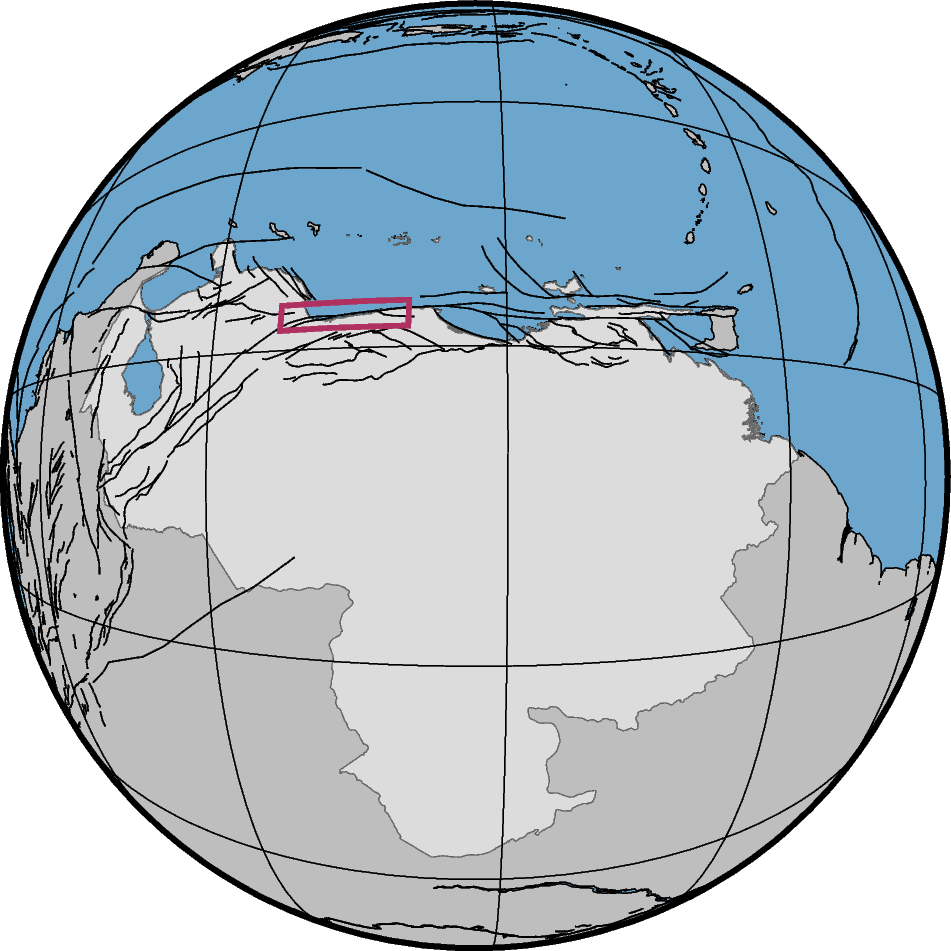

In [89]:
# Introductory figure base
fig = pygmt.Figure()

# Configuration for the 'current figure'.
pygmt.config(MAP_FRAME_TYPE="fancy")
#pygmt.config(FORMAT_GEO_MAP="ddd")
pygmt.config(FONT_ANNOT_PRIMARY="8p")
pygmt.config(FONT_ANNOT_SECONDARY="6p")

fig.coast(
    projection="G-65.5/8/8c+z200",
    region="g",
    dcw="VE+p0.2p,gray40+ggainsboro",
    land="gray",
    water="skyblue3",
    shorelines="0.25p,black",
    frame=["xa5g5", "ya5g5", "WSEN"]
)
fig.plot(data=gdf, pen="0.3p,black")
rectangle = [[whole_region[0], whole_region[2], whole_region[1], whole_region[3]]]
fig.plot(data=rectangle,style="r+s", pen="1.25p,maroon")


fig.savefig('/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/IntroMapParts/VEinset.pdf',dpi=300)
fig.show()

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)


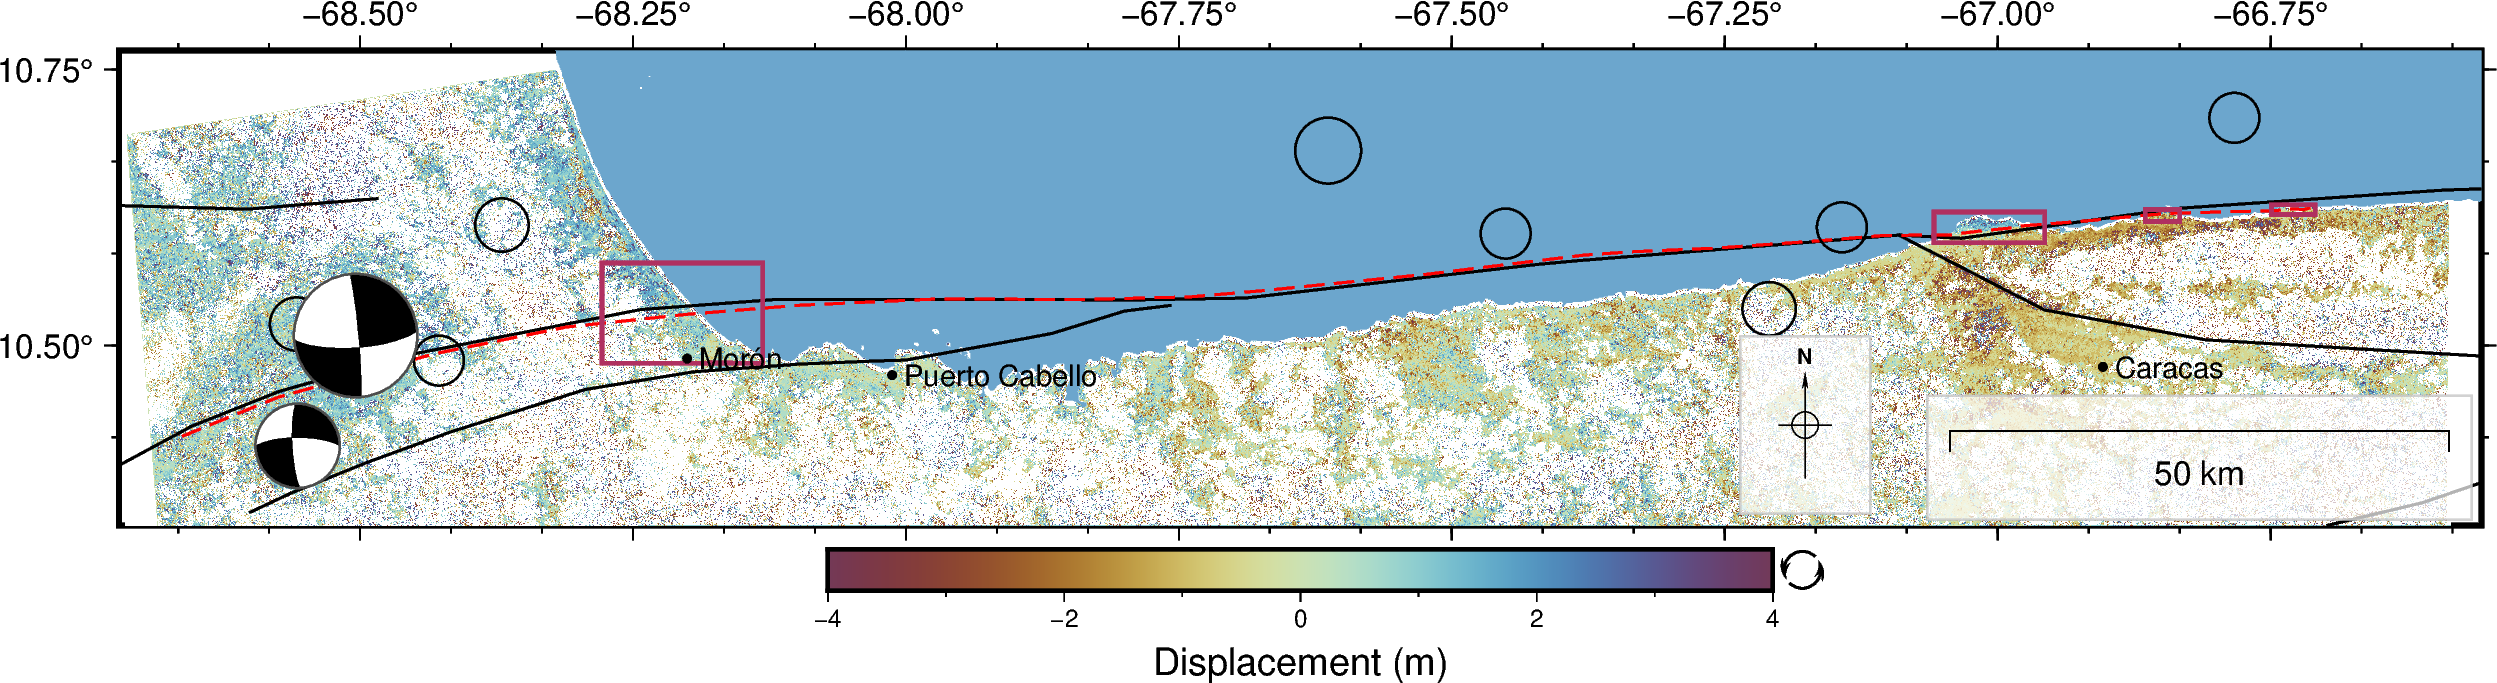

In [90]:
# Introductory figure base
fig = pygmt.Figure()

# Configuration for the 'current figure'.
pygmt.config(MAP_FRAME_TYPE="plain")
pygmt.config(FORMAT_GEO_MAP="ddd.xx")
pygmt.config(FONT_ANNOT_PRIMARY="8p")
pygmt.config(FONT_ANNOT_SECONDARY="6p")

# Plot the base map of the main figure. 
fig.basemap(region=whole_region, projection="M20c", frame=["WNse", "af"])

pygmt.makecpt(cmap='SCM/romaO',series=[-4,4],background='o')

fig.grdimage(grid=im,cmap=True)

fig.coast(water='skyblue3')
fig.plot(data=gdf, pen="0.6p,black")
fig.plot(data=simple_trace, pen="0.6p,red,-")
rectangle = [[laguaira[0], laguaira[2], laguaira[1], laguaira[3]]]
fig.plot(data=rectangle, style="r+s", pen="1p,maroon")
rectangle = [[caraballeda[0], caraballeda[2], caraballeda[1], caraballeda[3]]]
fig.plot(data=rectangle, style="r+s", pen="1p,maroon")
rectangle = [[naiguata_camuri[0], naiguata_camuri[2], naiguata_camuri[1], naiguata_camuri[3]]]
fig.plot(data=rectangle, style="r+s", pen="1p,maroon")
rectangle = [[west_region[0], west_region[2], west_region[1], west_region[3]]]
fig.plot(data=rectangle, style="r+s", pen="1p,maroon")

fig.plot(x=city_df.lon,y=city_df.lat,style="c0.08c",fill='black')
fig.text(x=city_df.lon,y=city_df.lat,text=city_df.city,font="7p,Helvetica,black",justify="LM",offset="0.10c/0c")

# Aftershocks
aft = gpd.read_file('https://earthquake.usgs.gov/fdsnws/event/1/query.geojson?starttime=2026-06-24%2022:05:12&endtime=2026-07-14%2023:59:59&maxlatitude=11.148&minlatitude=9.722&maxlongitude=-65.808&minlongitude=-69.521&minmagnitude=2.5&orderby=time')
fig.plot(
    x=aft.geometry.x,
    y=aft.geometry.y,
    # Apply power law so sizes scale well for magnitude
    size=0.02 * (2 ** aft["mag"]),
    style="cc", # c = circle, c = in centimeters
    fill=None,
    pen="0.5p,black"
)
fig.meca(spec={'strike':270,'dip':74,'rake':-169,'magnitude':7.17},longitude=-68.557,latitude=10.409,depth=27.6,convention='aki',
         scale='0.5c',compression_fill="black",pen="0.5p,gray30,solid",)
fig.meca(spec={'strike':86,'dip':74,'rake':-176,'magnitude':7.48},longitude=-68.504,latitude=10.509,depth=10,convention='aki',
         scale='0.7c',compression_fill="black",pen="0.5p,gray30,solid",)


fig.basemap(map_scale='JBR+w50k+o-4.5c/-0.8c+lkm',box="+c0.1/0.3+gwhite@30+p0.5p,grey@30,solid",rose='jBR+l,,,N+o5.5/0.4+w0.9c')
fig.colorbar(frame=['xaf+lDisplacement (m)'],position="JBC+w8c/0.35c+h+o0c/0.2c")

fig.savefig('/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/IntroMapParts/Deformation.pdf',dpi=300)

fig.show()

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)
makecpt [ERROR]: gmt_truncate_cpt error: z_low = -4 less than lowest z (0)


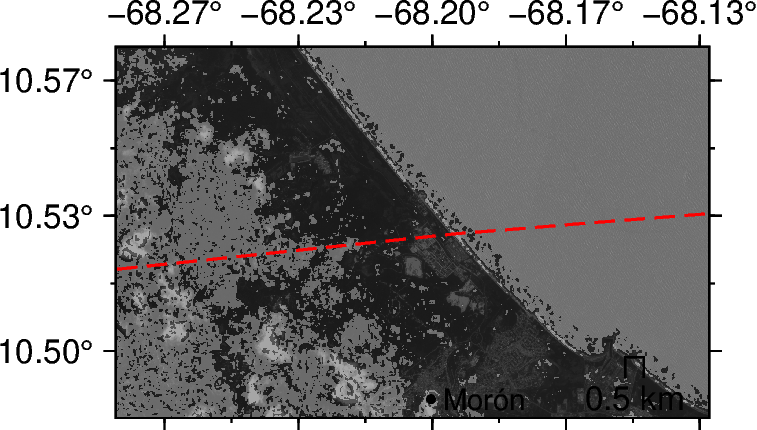

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)
makecpt [ERROR]: gmt_truncate_cpt error: z_low = -4 less than lowest z (0)


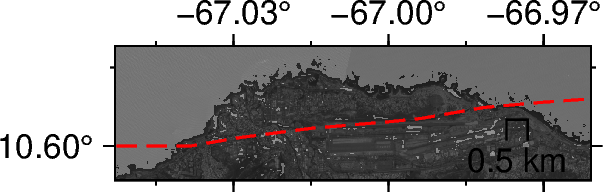

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)
makecpt [ERROR]: gmt_truncate_cpt error: z_low = -4 less than lowest z (0)


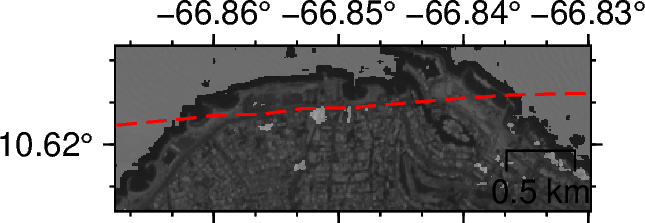

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)
makecpt [ERROR]: gmt_truncate_cpt error: z_low = -4 less than lowest z (0)


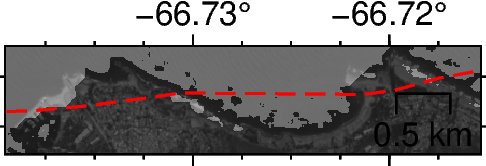

In [ ]:
# City boxes
names = ['west_region','laguaira','carabadella','naiguata_camuri']
width = [5,4,4,4]
for width,name,reg in zip(width,names,[west_region,laguaira,carabadella,naiguata_camuri]):
    # Introductory figure base
    fig = pygmt.Figure()

    # Configuration for the 'current figure'.
    pygmt.config(MAP_FRAME_TYPE="plain")
    pygmt.config(FORMAT_GEO_MAP="ddd.xx")
    pygmt.config(FONT_ANNOT_PRIMARY="8p")
    pygmt.config(FONT_ANNOT_SECONDARY="6p")

    # Plot the base map of the main figure. 
    fig.basemap(region=reg, projection=f"M{width}c", frame=["WNse", "af"])
    #fig.coast(water='skyblue3')

    # Imagery
    pygmt.makecpt(cmap="gray", series=[-170,3000])
    fig.grdimage(grid=imS2, cmap=True)

    pygmt.makecpt(cmap='SCM/romaO',series=[-7,7],background='o')
    fig.grdimage(grid=im,cmap=True,transparency=30)

    fig.plot(data=simple_trace, pen="0.6p,red,-")

    fig.plot(x=city_df.lon,y=city_df.lat,style="c0.08c",fill='black')
    fig.text(x=city_df.lon,y=city_df.lat,text=city_df.city,font="7p,Helvetica,black",justify="LM",offset="0.10c/0c")

    fig.basemap(map_scale='JBR+w0.5k+o-0.7c/-0.5c+lkm')

    fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/IntroMapParts/Deformation_{name}.pdf',dpi=300)

    fig.show()

## Wells and Coppersmith


In [34]:
215*0.75

161.25

In [37]:
# Mw = (log(Mo) - 16.1)*2/3
Mo = 2.122e+20+7.277e+19 # in N-m; where 1 Nm = 10**-7 Dyne cm
Mw = 2/3*(np.log10(Mo*10**7)-16.1)
L = 250 # technically length at depth
# log(AD) = a+b*Mw
a = -6.32
b = 0.9
ad = 10**(a+b*Mw)
print('Combined Magnitude:',Mw)
print('Average Displacement',ad)
# log(SRL) = a+b*Mw
a = -3.55
b = 0.74
srl = 10**(a+b*Mw)
print('Surface rupture length',srl)
# log(RLD) = a+b*Mw
a = -2.57
b = 0.62
rld = 10**(a+b*Mw)
print('Rupture length at depth',rld)

Combined Magnitude: 7.569866094929104
Average Displacement 3.1108529710579056
Surface rupture length 112.64214455181114
Rupture length at depth 132.8363637814641


In [41]:
# Thingbaijam et al. 2017
a = -1.473
b = 0.276

D = 10**(a + b * np.log10(L*1000))
print('Average Displacement',D)

Average Displacement 1.0395166321672462


## Figure 2. Point deformation fields

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)
/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)


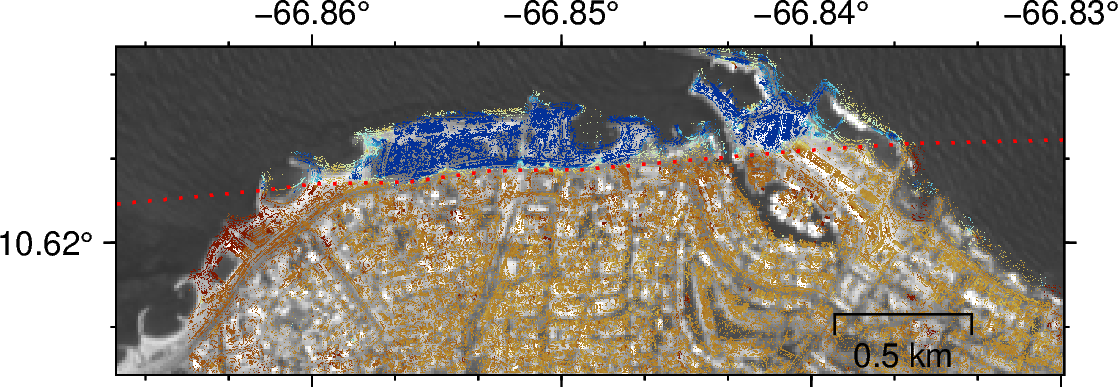

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)
/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)


: 

In [ ]:
# City boxes
names = ['laguaira','caraballeda','naiguata','camuri']
dE = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_CatiaLaMar.tif', 
      '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_caraballeda.tif', 
      '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20251227_20260626_EW_Naiguata.tif',
      '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toGE1_20251220_20260705_EW_CamuriGrande.tif']
json_files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/Catia La Mar_Profiles.geojson', 
        '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/caraballeda_Profiles.geojson', 
        '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/Naiguata_Profiles.geojson',
        '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/Camuri Grande_Profiles.geojson']
width = [8,8,5,5]
for width,defo,name,reg,json in zip(width[1:],dE[1:],names[1:],[laguaira,caraballeda,naiguata,camuri][1:],json_files[1:]):
    # Introductory figure base
    fig = pygmt.Figure()

    # Configuration for the 'current figure'.
    pygmt.config(MAP_FRAME_TYPE="plain")
    pygmt.config(FORMAT_GEO_MAP="ddd.xx")
    pygmt.config(FONT_ANNOT_PRIMARY="8p")
    pygmt.config(FONT_ANNOT_SECONDARY="6p")

    # Plot the base map of the main figure. 
    fig.basemap(region=reg, projection=f"M{width}c", frame=["WNse", "af"])
    #fig.coast(water='skyblue3')

    # Imagery
    pygmt.makecpt(cmap="gray", series=[-170,3000])
    fig.grdimage(grid=imS2, cmap=True)
    minc, maxc = -1, 2.5
    pygmt.makecpt(cmap='roma',series=[minc,maxc])
    im = rioxarray.open_rasterio(defo,masked=True)
    im = im.rio.reproject('EPSG:4326')
    fig.grdimage(grid=im,cmap=True,nan_transparent=True)

    fig.plot(data=simple_trace, pen="0.75p,red,.")

    ## Read GeoJSON
    #erf_lines = gpd.read_file(json)
    #erf_lines['slip_magnitude'] = pd.to_numeric(erf_lines['slip_magnitude'] *-1)
    ## Convert to lon/lat for PyGMT
    #erf_lines = erf_lines.to_crs("EPSG:4326")
#
    ## Make CPT from attribute
    #pygmt.makecpt(
    #    cmap="magma",truncate=False,
    #    series=[0,3.5]
    #)
    ## Plot polygons colored by attribute
    #for i in range(len(erf_lines)):
    #    line = erf_lines.iloc[i]
    #    zval = line.slip_magnitude
    #    fig.plot(
    #        x=line.geometry.xy[0],
    #        y=line.geometry.xy[1],
    #        straight_line=True,
    #        pen="0.5p,+z",
    #        cmap=True,
    #        zvalue=zval
    #    )

    fig.basemap(map_scale='JBR+w0.5k+o-1.93c/-0.5c+lkm')

    fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/DefoMapParts/HighResDeformation_{name}.png',dpi=300)

    fig.show()

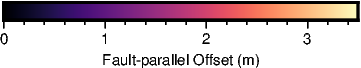

In [36]:
fig = pygmt.Figure()
pygmt.config(FONT_ANNOT_PRIMARY="8p", FONT_LABEL="8p")
pygmt.config(MAP_LABEL_OFFSET="0.1p")
pygmt.makecpt(cmap='magma',series=[0,3.5])
fig.colorbar(frame=['xaf+lFault-parallel Offset (m)'],position="JBC+w3c/0.15c+o0c/-0.2c",cmap=True)
fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/DefoMapParts/Colorbar_Offset.png',dpi=300,transparent=True)
fig.show()

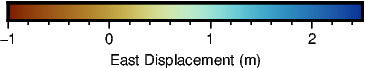

In [35]:
fig = pygmt.Figure()
pygmt.config(FONT_ANNOT_PRIMARY="8p", FONT_LABEL="8p")
pygmt.config(MAP_LABEL_OFFSET="0.1p")
pygmt.makecpt(cmap='roma',series=[minc,maxc],background=True)
fig.colorbar(frame=['xaf+lEast Displacement (m)'],position="JBC+w3c/0.15c+o0c/0c",cmap=True)
fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/DefoMapParts/Colorbar_{name}.png',dpi=300,transparent=True)
fig.show()

## Make Profiles At Each AOI

In [3]:
from matplotlib.patches import Rectangle
from shapely.ops import linemerge
def swath_corners(x0, y0, az_deg, length, width):
    az = az_deg * np.pi/180

    # shift vectors
    u_par = np.array([np.sin(az), np.cos(az)])
    u_perp = np.array([np.cos(az), -np.sin(az)])

    hl = length / 2
    hw = width / 2

    shift = np.array([
        np.dot(np.array([-hl,hw]), np.array([u_perp,u_par])),
        np.dot(np.array([hl,hw]), np.array([u_perp,u_par])),
        np.dot(np.array([hl,-hw]), np.array([u_perp,u_par])),
        np.dot(np.array([-hl,-hw]), np.array([u_perp,u_par]))

    ])

    corners = np.array([
        [x0+shift[0,0],y0+shift[0,1]],
        [x0+shift[1,0],y0+shift[1,1]],
        [x0+shift[2,0],y0+shift[2,1]],
        [x0+shift[3,0],y0+shift[3,1]]
    ])

    return corners

### Moron

In [104]:
crs = 'EPSG:32619'

swath_dict = {
    'Moron':{'swath_az':50,
             'fault_az':83,
             'swath_width':500,
             'swath_length':20000,# 15000
             'resolution':10,
             'x':[587288],
             'y':[1163895],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_20260505_20260629_EW_masked.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_02260505_20260629_NS_masked.tif',
             'map_swath':10000,
             'map_resolution': 100}}

fault = simple_trace.to_crs('EPSG:32619')

Moron
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-12.903099971337186), np.float64(-9995.0), 0, np.float64(-6.454777374355771e-05), np.float64(-6.454777374355771e-05)), (inf, np.float64(12.903099971337186), np.float64(9995.0), 5000, np.float64(6.454777374355771e-05), np.float64(6.454777374355771e-05)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-7.191561504394127), np.float64(-9995.0), 0, np.float64(-3.597579541968047e-05), np.float6

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


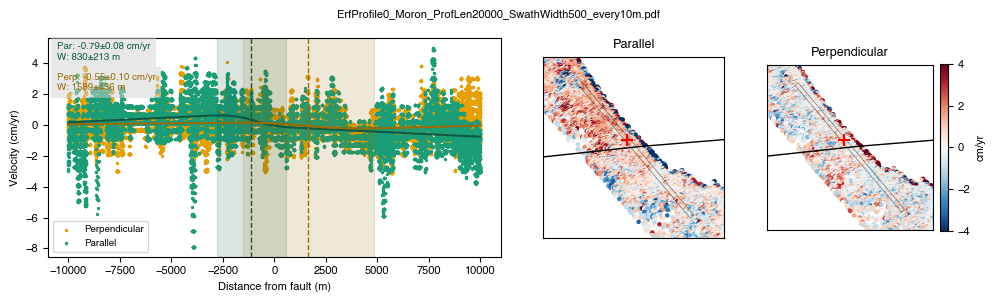

In [105]:
plot = True

points_dfs = []

for key in list(swath_dict.keys()):
    print(key)
    # Read the rasters
    ns = rasterio.open(swath_dict[key]['nsfile'],masked=True)
    ew = rasterio.open(swath_dict[key]['ewfile'],masked=True)

    xs = swath_dict[key]['x']
    ys = swath_dict[key]['y']

    for i in range(len(xs)):
    
        df = pd.DataFrame({'x':xs,
                           'y':ys})
        df["region"] = key

        x0, y0 = xs[i], ys[i]
    
        ns_samps, spts, dists = tt.sample_swath(
            ns, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ns_samps[ns_samps == -9999] = np.nan
    
        ew_samps, spts, dists = tt.sample_swath(
            ew, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ew_samps[ew_samps == -9999] = np.nan
    
        par, perp = tt.projectParPerp(
            ns_samps - np.nanmean(ns_samps),
            ew_samps - np.nanmean(ew_samps),
            swath_dict[key]['fault_az']
        )
        (
            par_intercept,
            par_total_offset,
            par_fault_loc,
            par_shear_width,
            par_total_offset_sig,
            par_fault_loc_sig,
            par_shear_width_sig,
            par_slope1,
            par_slope1_sig,
            par_slope2,
            par_slope2_sig,
            par_fzw_offset,
            par_ep_offset,
            par_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(par, dists)
    
        par_fit_sig = np.nanstd(
            par
            - tt.erf_function_twoslope(
                dists,
                par_intercept,
                par_total_offset,
                par_fault_loc,
                par_shear_width,
                par_slope1,
                par_slope2,
            )
        )
    
        df.loc[i, "par_intercept"] = par_intercept
        df.loc[i, "par_total_offset"] = par_total_offset
        df.loc[i, "par_fault_loc"] = par_fault_loc
        df.loc[i, "par_shear_width"] = par_shear_width
        df.loc[i, "par_total_offset_sig"] = par_total_offset_sig
        df.loc[i, "par_fault_loc_sig"] = par_fault_loc_sig
        df.loc[i, "par_shear_width_sig"] = par_shear_width_sig
        df.loc[i, "par_slope1"] = par_slope1
        df.loc[i, "par_slope1_sig"] = par_slope1_sig
        df.loc[i, "par_slope2"] = par_slope2
        df.loc[i, "par_slope2_sig"] = par_slope2_sig
        df.loc[i, "par_fzw_offset"] = par_fzw_offset
        df.loc[i, "par_ep_offset"] = par_ep_offset
        df.loc[i, "par_fit_sig"] = par_fit_sig
    
        (
        perp_intercept,
        perp_total_offset,
        perp_fault_loc,
        perp_shear_width,
        perp_total_offset_sig,
        perp_fault_loc_sig,
        perp_shear_width_sig,
        perp_slope1,
        perp_slope1_sig,
        perp_slope2,
        perp_slope2_sig,
        perp_fzw_offset,
        perp_ep_offset,
        perp_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(perp, dists)

        perp_fit_sig = np.nanstd(
            perp
            - tt.erf_function_twoslope(
                dists,
                perp_intercept,
                perp_total_offset,
                perp_fault_loc,
                perp_shear_width,
                perp_slope1,
                perp_slope2,
            )
        )

        df.loc[i, "perp_intercept"] = perp_intercept
        df.loc[i, "perp_total_offset"] = perp_total_offset
        df.loc[i, "perp_fault_loc"] = perp_fault_loc
        df.loc[i, "perp_shear_width"] = perp_shear_width
        df.loc[i, "perp_total_offset_sig"] = perp_total_offset_sig
        df.loc[i, "perp_fault_loc_sig"] = perp_fault_loc_sig
        df.loc[i, "perp_shear_width_sig"] = perp_shear_width_sig
        df.loc[i, "perp_slope1"] = perp_slope1
        df.loc[i, "perp_slope1_sig"] = perp_slope1_sig
        df.loc[i, "perp_slope2"] = perp_slope2
        df.loc[i, "perp_slope2_sig"] = perp_slope2_sig
        df.loc[i, "perp_fzw_offset"] = perp_fzw_offset
        df.loc[i, "perp_ep_offset"] = perp_ep_offset
        df.loc[i, "perp_fit_sig"] = perp_fit_sig

        if plot == True:
            # ===============================
            # PLOTTING (WITH FAULT TRACE + INTERSECTIONS)
            # ===============================    
            plt.style.use('seaborn-v0_8-colorblind')

            fig, axes = plt.subplots(
                1, 3,
                figsize=(10, 3),
                gridspec_kw={'width_ratios': [2.5, 1, 1]}
            )

            ax_prof, ax_par_map, ax_perp_map = axes

            # =========================
            # 1) PROFILE GEOMETRY
            # =========================

            x0, y0 = xs[i], ys[i]
            rad = np.deg2rad(swath_dict[key]['swath_az'])

            # unit vector perpendicular to fault (profile direction)
            u_perp = np.array([np.cos(rad), -np.sin(rad)])

            # profile endpoints
            p1 = np.array([x0, y0]) - u_perp * (swath_dict[key]['swath_length'] / 2)
            p2 = np.array([x0, y0]) + u_perp * (swath_dict[key]['swath_length'] / 2)

            # =========================
            # 3) PROFILE PLOT
            # =========================
            # data
            ax_prof.scatter(dists, perp, s=2, c='#E69F00', label='Perpendicular')
            ax_prof.scatter(dists, par, s=2, c='#1B9E77', label='Parallel')

            # fits
            ax_prof.plot(
                dists,
                tt.erf_function_twoslope(
                    dists,
                    par_intercept, par_total_offset, par_fault_loc,
                    par_shear_width, par_slope1, par_slope2
                ),
                color="#0F5943", lw=1.5
            )
            # ERF fault (center)
            ax_prof.axvline(par_fault_loc, color="#0F5943", ls='--', lw=1)# label='ERF fault')
            # shear zone shading (parallel)
            ax_prof.axvspan(
                par_fault_loc-2*par_shear_width,
                par_fault_loc+2*par_shear_width,
                color="#0F5943", alpha=0.15
            )

            ax_prof.plot(
                dists,
                tt.erf_function_twoslope(
                    dists,
                    perp_intercept, perp_total_offset, perp_fault_loc,
                    perp_shear_width, perp_slope1, perp_slope2
                ),
                color="#9A6A03", lw=1.5
            )

            # shear zone shading (perp)
            ax_prof.axvline(perp_fault_loc, color="#9A6A03", ls='--', lw=1)# label='ERF fault')
            ax_prof.axvspan(
                perp_fault_loc-2*perp_shear_width,
                perp_fault_loc+2*perp_shear_width,
                color="#9A6A03", alpha=0.15
            )

            bbox_props = dict(facecolor='lightgrey', alpha=0.5, edgecolor='none')

            ax_prof.text(
                0.02, 0.98,
                f'Par: {par_total_offset:.2f}±{4*par_total_offset_sig:.2f} cm/yr\n'
                f'W: {par_shear_width:.0f}±{4*par_shear_width_sig:.0f} m',
                transform=ax_prof.transAxes,
                va='top',
                fontsize=7,
                color="#0F5943",
                bbox=bbox_props
                )

            ax_prof.text(
                0.02, 0.84,
                f'Perp: {perp_total_offset:.2f}±{4*perp_total_offset_sig:.2f} cm/yr\n'
                f'W: {perp_shear_width:.0f}±{4*perp_shear_width_sig:.0f} m',
                transform=ax_prof.transAxes,
                va='top',
                fontsize=7,
                color="#9A6A03",
                bbox=bbox_props)

            
            # labels
            ax_prof.set_xlabel('Distance from fault (m)')
            ax_prof.set_ylabel('Velocity (cm/yr)')
            ax_prof.legend(fontsize=7, loc='lower left')

            # =========================
            # 4) MAP DATA
            # =========================

            ns_map_samps, map_pts, map_dists = tt.sample_swath(
                ns, x0, y0,
                swath_dict[key]['swath_az'],
                swath_dict[key]['swath_length']*1.5, swath_dict[key]['map_swath'], 
                swath_dict[key]['map_resolution'], crs=crs
            )
            ns_map_samps[ns_map_samps == -9999] = np.nan

            ew_map_samps, map_pts, map_dists = tt.sample_swath(
                ew, x0, y0,
                swath_dict[key]['swath_az'],
                swath_dict[key]['swath_length']*1.5, swath_dict[key]['map_swath'], 
                swath_dict[key]['map_resolution'], crs=crs
            )
            ew_map_samps[ew_map_samps == -9999] = np.nan

            par_map, perp_map = tt.projectParPerp(
                ns_map_samps,
                ew_map_samps,
                swath_dict[key]['fault_az']
            )

            # =========================
            # 5) MAP PLOTS
            # =========================

            # parallel
            ax_par_map.scatter(
                map_pts[:,0], map_pts[:,1],
                c=par_map, s=5, cmap='RdBu_r',
                vmin=-4, vmax=4
            )

            # perpendicular
            ax_perp_map.scatter(
                map_pts[:,0], map_pts[:,1],
                c=perp_map, s=5, cmap='RdBu_r',
                vmin=-4, vmax=4
            )
            # Perpendicular colorbar
            cbar_perp = plt.colorbar(
                ax_perp_map.collections[0],
                ax=ax_perp_map,
                fraction=0.046,
                pad=0.04
            )
            cbar_perp.set_label('cm/yr', fontsize=8)

            # fault trace
            fault.plot(ax=ax_par_map, color='k', linewidth=1)
            fault.plot(ax=ax_perp_map, color='k', linewidth=1)

            ax_par_map.set_title('Parallel', fontsize=9)
            ax_perp_map.set_title('Perpendicular', fontsize=9)

            # =========================
            # 6) SWATH BOX + LIMITS
            # =========================

            xll, yll = swath_corners(
                x0, y0,
                swath_dict[key]['swath_az'],
                swath_dict[key]['swath_length'], swath_dict[key]['swath_width']
            )[-1]

            pad = swath_dict[key]['map_swath']

            for ax in [ax_par_map, ax_perp_map]:
                ax.set_xlim(x0 - pad, x0 + pad)
                ax.set_ylim(y0 - pad, y0 + pad)

                ax.add_patch(Rectangle(
                    [xll, yll],
                     swath_dict[key]['swath_length'], swath_dict[key]['swath_width'],
                    angle=-swath_dict[key]['swath_az'],
                    facecolor='none',
                    edgecolor='black',
                    linewidth=0.5,
                    alpha=0.5
                ))

                ax.set_aspect('equal')
                ax.set_xticks([])
                ax.set_yticks([])

            # =========================
            # 7) ERF FAULT LOCATION ON MAP
            # =========================

            fault_xy = np.array([x0, y0]) + u_perp * par_fault_loc

            ax_par_map.plot(fault_xy[0], fault_xy[1], 'r+', ms=8, mew=1.5)
            ax_perp_map.plot(fault_xy[0], fault_xy[1], 'r+', ms=8, mew=1.5)

            fig.suptitle(f'ErfProfile{i}_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{ swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m.pdf')

            # nudge map panels slightly right
            pos_par = ax_par_map.get_position()
            pos_perp = ax_perp_map.get_position()

            shift = 0.02  # adjust if needed

            ax_par_map.set_position([pos_par.x0 + shift, pos_par.y0, pos_par.width, pos_par.height])
            ax_perp_map.set_position([pos_perp.x0 + shift, pos_perp.y0, pos_perp.width, pos_perp.height])
            # tighten spacing between the two map panels
            gap_reduce = 0.015

            ax_perp_map.set_position([
                ax_par_map.get_position().x1 + gap_reduce,
                pos_perp.y0,
                pos_perp.width,
                pos_perp.height
            ])
            # =========================
            plt.tight_layout()
            plt.savefig(
                    f'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfile{i}'
                    f'_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m.pdf',
                    dpi=300
                )
            plt.show()
            
    points_dfs.append(df)

points = pd.concat(points_dfs, ignore_index=True)
points["easting"] = points["x"]
points["northing"] = points["y"]
    # Save results
points.to_csv(
        f'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{ swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m.csv',
        float_format='%.4f'
    )

### Points

In [ ]:
crs = 'EPSG:32619'

swath_dict = {
    'Catia La Mar':{
             'swath_width':50,
             'swath_length':2000,
             'resolution':0.4,
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CatiaLaMar_to26_masked_ocean.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CatiaLaMar_to26_masked_ocean.tif',
             'fault_file':'/Volumes/Venezuela/Venezuela2026Doublet/GIS/CatiaLaMarSimpleTraceEPSG4326.geojson',
             'map_swath':3000,
             'map_resolution': 10},
    'caraballeda':{
             'swath_width':50,
             'swath_length':2000,
             'resolution':0.4,
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_caraballeda.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_NS_caraballeda.tif',
             'fault_file':'/Volumes/Venezuela/Venezuela2026Doublet/GIS/caraballedaSimpleTraceEPSG4326.geojson',
             'map_swath':3000,
             'map_resolution': 10},
    'Naiguata':{
             'swath_width':50,
             'swath_length':2000,
             'resolution':0.4,
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_Naiguata_masked_ocean.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_Naiguata_masked_ocean.tif',
             'fault_file':'/Volumes/Venezuela/Venezuela2026Doublet/GIS/NaiguataSimpleTraceEPSG4326.geojson',
             'map_swath':3000,
             'map_resolution': 10},
    'Camuri Grande':{
             'swath_width':50,
             'swath_length':2000,
             'resolution':0.4,
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CamuriGrande_masked_ocean.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CamuriGrande_masked_ocean.tif',
             'fault_file':'/Volumes/Venezuela/Venezuela2026Doublet/GIS/CamuriGrandeSimpleTraceEPSG4326.geojson',
             'map_swath':3000,
             'map_resolution': 10},
    'Catia La Mar 25':{
             'swath_width':50,
             'swath_length':2000,
             'resolution':0.4,
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CatiaLaMar_to25_masked_ocean.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CatiaLaMar_to25_masked_ocean.tif',
             'fault_file':'/Volumes/Venezuela/Venezuela2026Doublet/GIS/CatiaLaMarSimpleTraceEPSG4326.geojson',
             'map_swath':3000,
             'map_resolution': 10},
    'Catia La Mar AS':{
             'swath_width':50,
             'swath_length':2000,
             'resolution':0.4,
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CatiaLaMar_25to26_masked_ocean.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CatiaLaMar_25to26_masked_ocean.tif',
             'fault_file':'/Volumes/Venezuela/Venezuela2026Doublet/GIS/CatiaLaMarSimpleTraceEPSG4326.geojson',
             'map_swath':3000,
             'map_resolution': 10},
}

fault = simple_trace.to_crs('EPSG:32619')

Carabadella
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-6.972293787079582), np.float64(-999.7999999999431), 0, np.float64(-0.0003486844262392468), np.float64(-0.0003486844262392468)), (inf, np.float64(6.972293787079582), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0003486844262392468), np.float64(0.0003486844262392468)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-6.357120178042219), np.float64(-999.7

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


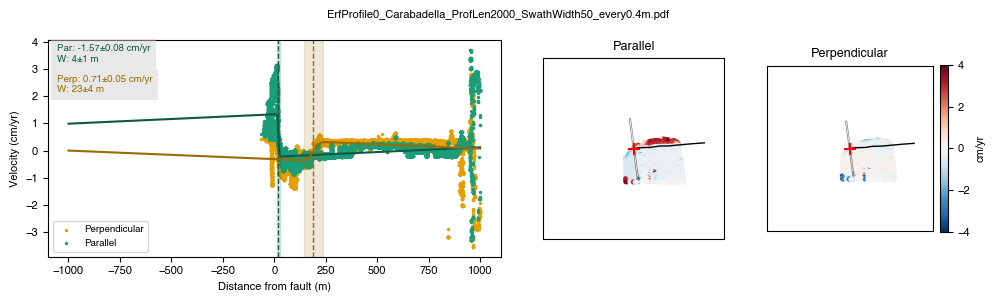

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.2649036701666585), np.float64(-999.7999999999431), 0, np.float64(-0.0002132878410765604), np.float64(-0.0002132878410765604)), (inf, np.float64(4.2649036701666585), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002132878410765604), np.float64(0.0002132878410765604)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.332125757972295), np.float64(-999.79999999994

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


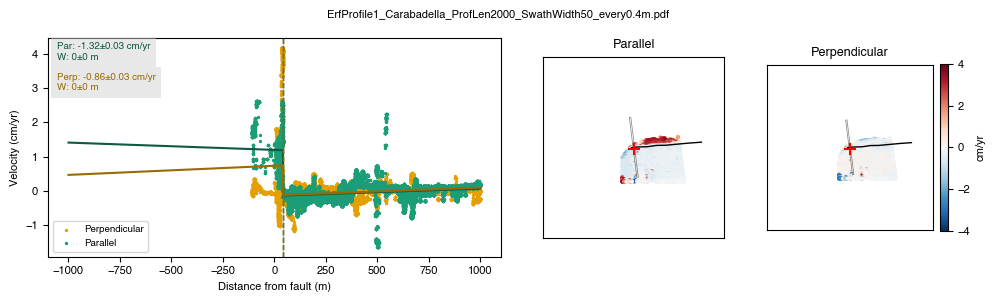

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-6.170360440146246), np.float64(-999.7999999999431), 0, np.float64(-0.0003085797379549208), np.float64(-0.0003085797379549208)), (inf, np.float64(6.170360440146246), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0003085797379549208), np.float64(0.0003085797379549208)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.5143786572311355), np.float64(-999.799999999943

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


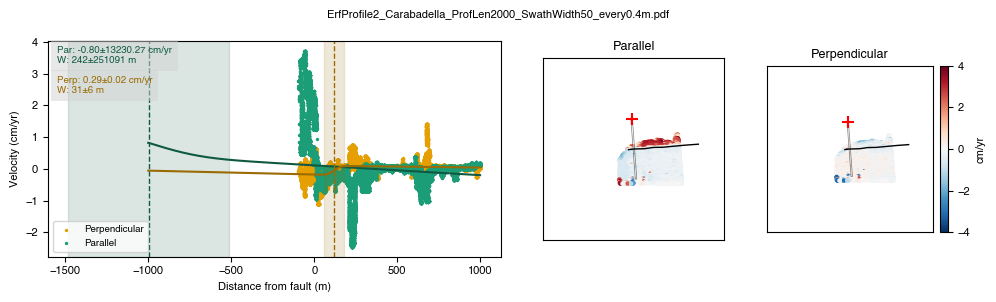

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.935356884883767), np.float64(-999.7999999999431), 0, np.float64(-0.00019680720568533662), np.float64(-0.00019680720568533662)), (inf, np.float64(3.935356884883767), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00019680720568533662), np.float64(0.00019680720568533662)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-1.9097624308567744), np.float64(-999.79999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


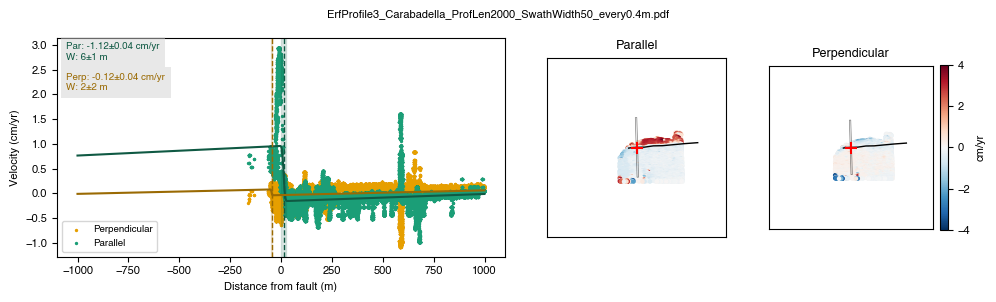

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.6337227436488257), np.float64(-999.7999999999431), 0, np.float64(-0.00018172248167878737), np.float64(-0.00018172248167878737)), (inf, np.float64(3.6337227436488257), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00018172248167878737), np.float64(0.00018172248167878737)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.3297365578644076), np.float64(-999.799999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


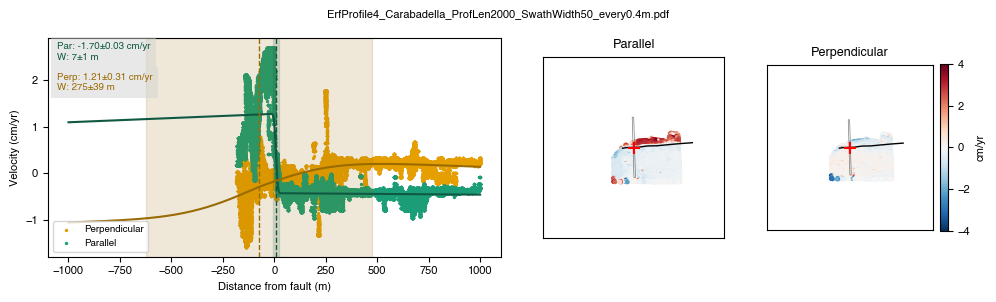

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-6.850108021443422), np.float64(-999.7999999999431), 0, np.float64(-0.00034257391585536164), np.float64(-0.00034257391585536164)), (inf, np.float64(6.850108021443422), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00034257391585536164), np.float64(0.00034257391585536164)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.496541271950637), np.float64(-999.799999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


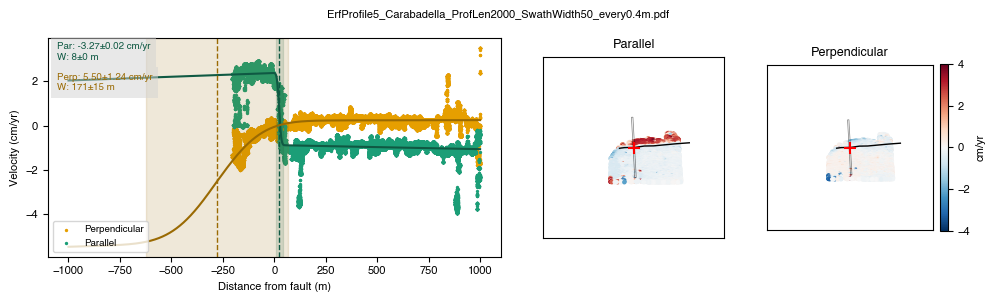

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.860858717197564), np.float64(-999.7999999999431), 0, np.float64(-0.00024309155417072615), np.float64(-0.00024309155417072615)), (inf, np.float64(4.860858717197564), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00024309155417072615), np.float64(0.00024309155417072615)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.89843605808234), np.float64(-999.7999999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


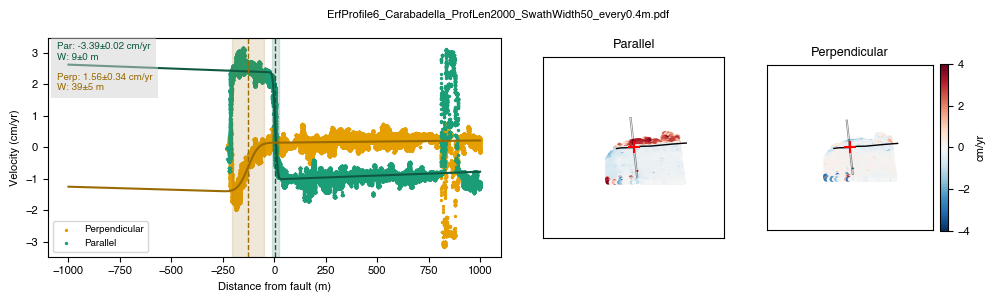

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.7036207995531925), np.float64(-999.7999999999431), 0, np.float64(-0.0002852380875951949), np.float64(-0.0002852380875951949)), (inf, np.float64(5.7036207995531925), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002852380875951949), np.float64(0.0002852380875951949)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.4209691652511767), np.float64(-999.7999999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


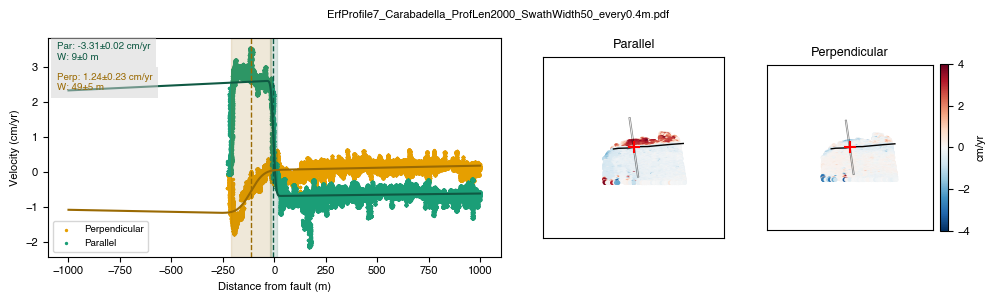

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.712423101909911), np.float64(-999.7999999999431), 0, np.float64(-0.0002356682887532596), np.float64(-0.0002356682887532596)), (inf, np.float64(4.712423101909911), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002356682887532596), np.float64(0.0002356682887532596)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.5630690617718503), np.float64(-999.799999999943

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


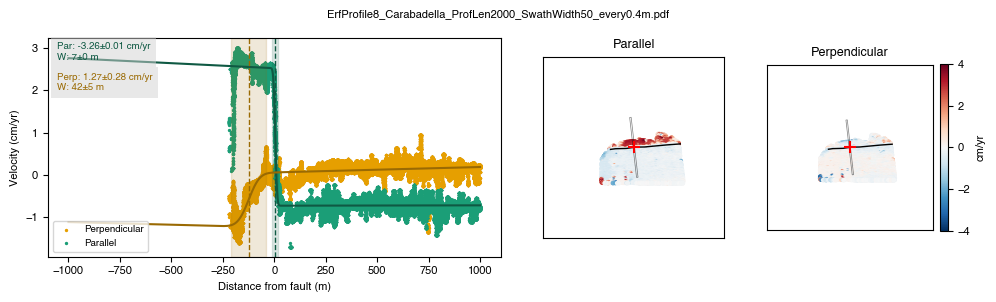

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.884778725544336), np.float64(-999.7999999999431), 0, np.float64(-0.00024428779383599785), np.float64(-0.00024428779383599785)), (inf, np.float64(4.884778725544336), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00024428779383599785), np.float64(0.00024428779383599785)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.449617012136661), np.float64(-999.799999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


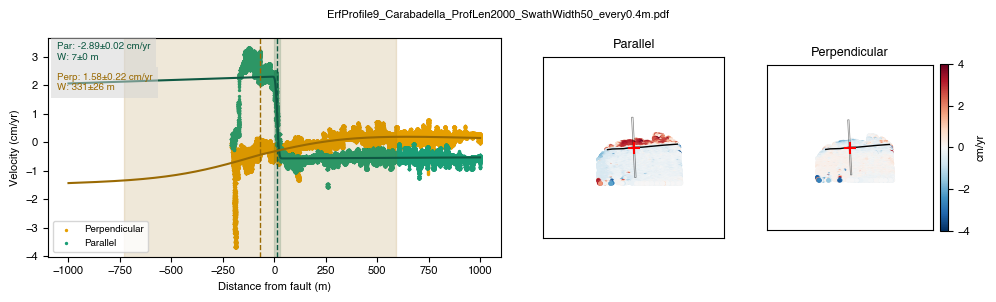

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.092112728206521), np.float64(-999.7999999999431), 0, np.float64(-0.00025465656772388534), np.float64(-0.00025465656772388534)), (inf, np.float64(5.092112728206521), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00025465656772388534), np.float64(0.00025465656772388534)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.4325416226041776), np.float64(-999.79999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


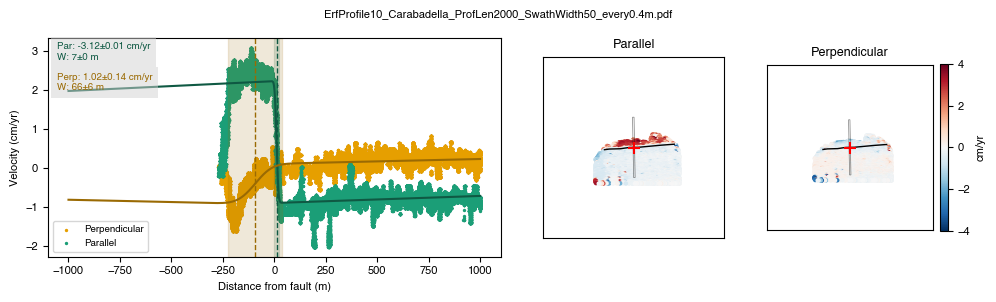

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.355496299780988), np.float64(-999.7999999999431), 0, np.float64(-0.00026782838066519767), np.float64(-0.00026782838066519767)), (inf, np.float64(5.355496299780988), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00026782838066519767), np.float64(0.00026782838066519767)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.194327546037898), np.float64(-999.799999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


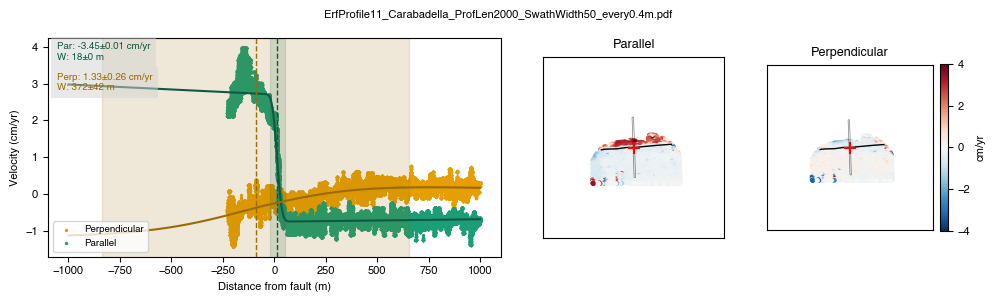

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.305002636977794), np.float64(-999.7999999999431), 0, np.float64(-0.00026530319248740226), np.float64(-0.00026530319248740226)), (inf, np.float64(5.305002636977794), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00026530319248740226), np.float64(0.00026530319248740226)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.945891197353509), np.float64(-999.799999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


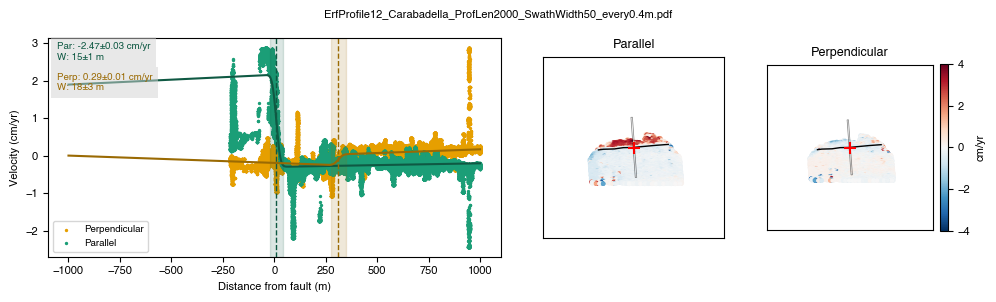

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.7032570327571115), np.float64(-999.7999999999431), 0, np.float64(-0.0002352098936165923), np.float64(-0.0002352098936165923)), (inf, np.float64(4.7032570327571115), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002352098936165923), np.float64(0.0002352098936165923)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-1.5180790580808456), np.float64(-999.7999999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


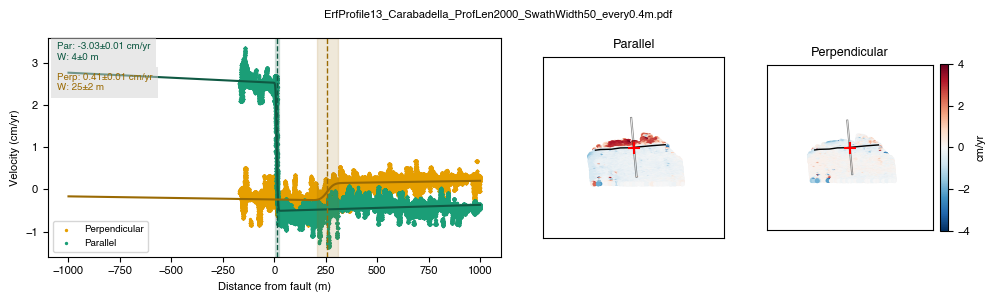

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.663913379154333), np.float64(-999.7999999999431), 0, np.float64(-0.00023324231742121414), np.float64(-0.00023324231742121414)), (inf, np.float64(4.663913379154333), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00023324231742121414), np.float64(0.00023324231742121414)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.4112268506624988), np.float64(-999.79999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


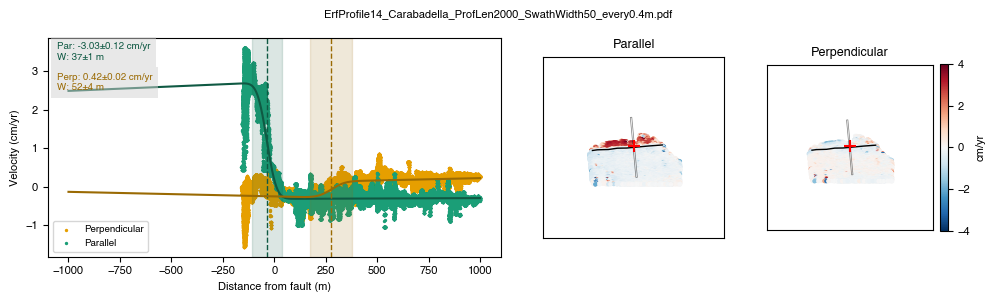

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.764944022013262), np.float64(-999.7999999999431), 0, np.float64(-0.0002382948600726912), np.float64(-0.0002382948600726912)), (inf, np.float64(4.764944022013262), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002382948600726912), np.float64(0.0002382948600726912)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.4004437112432155), np.float64(-999.799999999943

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


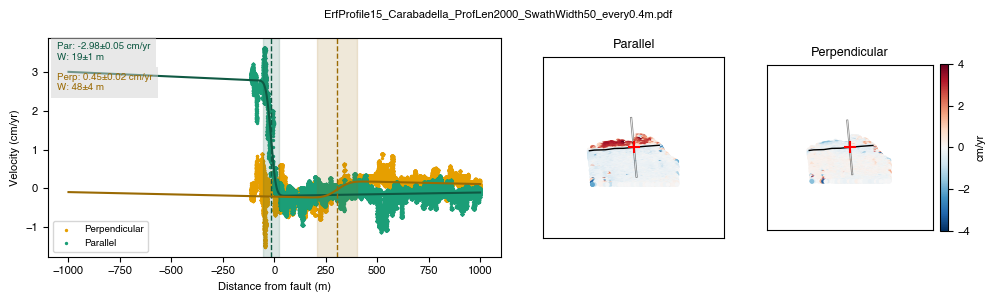

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.615146973693758), np.float64(-999.7999999999431), 0, np.float64(-0.00023080350938657832), np.float64(-0.00023080350938657832)), (inf, np.float64(4.615146973693758), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00023080350938657832), np.float64(0.00023080350938657832)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.456010431565627), np.float64(-999.799999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


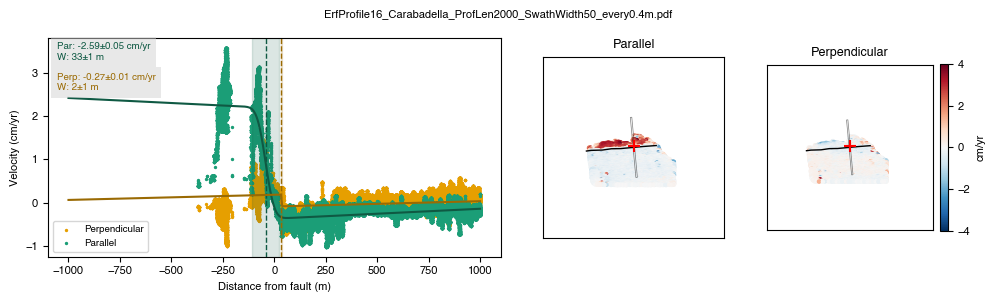

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-6.008880736584754), np.float64(-999.7999999999431), 0, np.float64(-0.00030050413765678614), np.float64(-0.00030050413765678614)), (inf, np.float64(6.008880736584754), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00030050413765678614), np.float64(0.00030050413765678614)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.0013803780048662), np.float64(-999.79999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


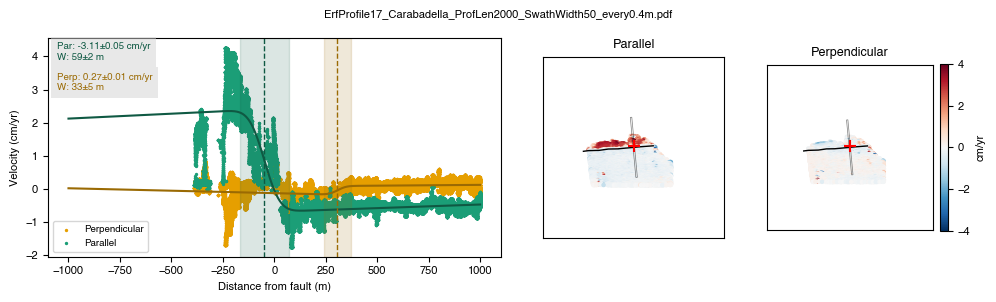

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.75552092849213), np.float64(-999.7999999999431), 0, np.float64(-0.0002378236111468494), np.float64(-0.0002378236111468494)), (inf, np.float64(4.75552092849213), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002378236111468494), np.float64(0.0002378236111468494)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.8596463931216887), np.float64(-999.7999999999431)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


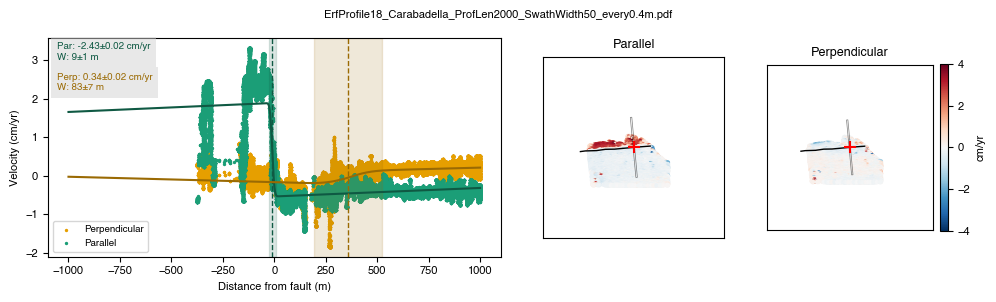

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.065670533115219), np.float64(-999.7999999999431), 0, np.float64(-0.00020332419149407134), np.float64(-0.00020332419149407134)), (inf, np.float64(4.065670533115219), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.00020332419149407134), np.float64(0.00020332419149407134)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.28575560070278), np.float64(-999.7999999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


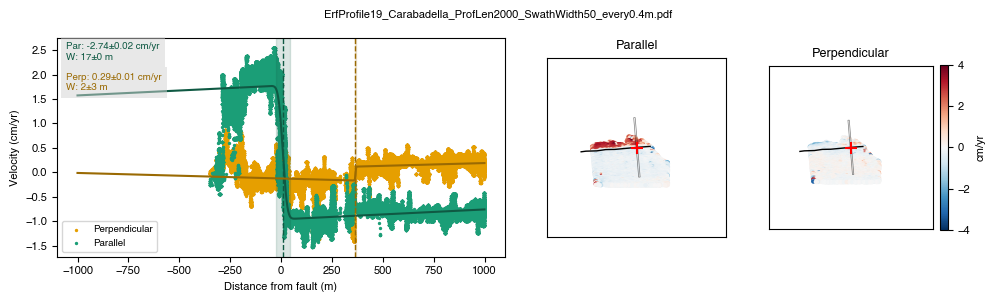

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.239183503170614), np.float64(-999.7999999999431), 0, np.float64(-0.0002620115774740404), np.float64(-0.0002620115774740404)), (inf, np.float64(5.239183503170614), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002620115774740404), np.float64(0.0002620115774740404)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.179831529617576), np.float64(-999.7999999999431

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


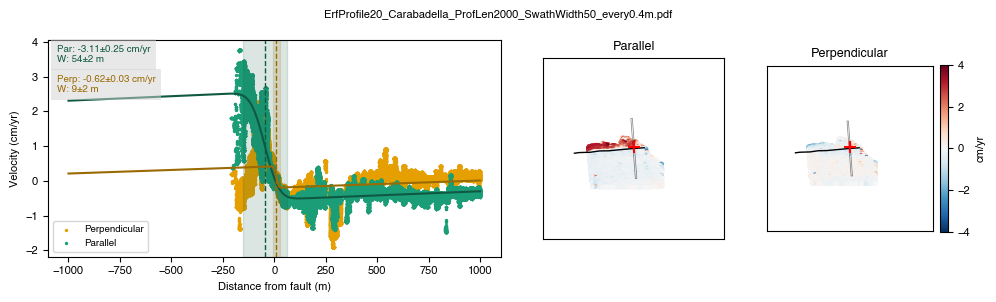

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-4.173750118235578), np.float64(-999.7999999999431), 0, np.float64(-0.0002087292517621432), np.float64(-0.0002087292517621432)), (inf, np.float64(4.173750118235578), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002087292517621432), np.float64(0.0002087292517621432)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.0686298178914115), np.float64(-999.799999999943

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


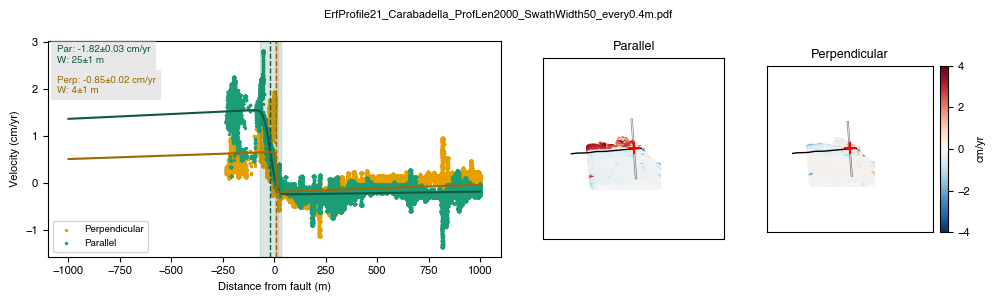

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-1.9524286883256248), np.float64(-999.7999999999431), 0, np.float64(-9.764096260880856e-05), np.float64(-9.764096260880856e-05)), (inf, np.float64(1.9524286883256248), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(9.764096260880856e-05), np.float64(9.764096260880856e-05)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-3.2015988372884823), np.float64(-999.7999999999

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


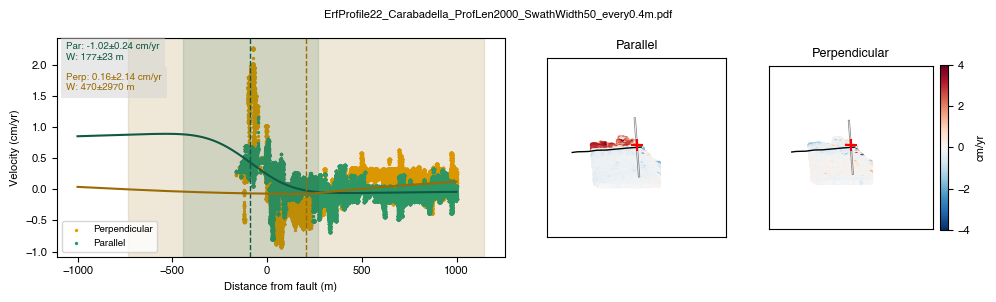

Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-5.094191235613454), np.float64(-999.7999999999431), 0, np.float64(-0.0002547605138834639), np.float64(-0.0002547605138834639)), (inf, np.float64(5.094191235613454), np.float64(999.7999999999431), np.float64(499.89999999997156), np.float64(0.0002547605138834639), np.float64(0.0002547605138834639)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.6771098991897726), np.float64(-999.799999999943

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


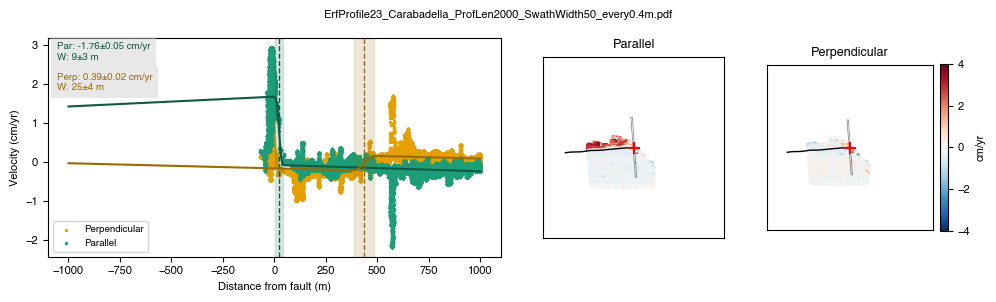

In [ ]:
from shapely.ops import linemerge
plot = True

for key in list(swath_dict.keys())[1:2]:
    print(key)
    # Read the rasters
    ns = rasterio.open(swath_dict[key]['nsfile'],masked=True)
    ew = rasterio.open(swath_dict[key]['ewfile'],masked=True)
    area_fault = gpd.read_file(swath_dict[key]['fault_file']).to_crs(crs)
    line = linemerge(area_fault.geometry.iloc[0])

    # Sample every 50 m
    d = np.arange(0, line.length, 100)
    pts = [line.interpolate(x) for x in d]

    xs = np.array([p.x for p in pts])
    ys = np.array([p.y for p in pts])

    # Central differences (forward/backward at ends)
    dx = np.gradient(xs)
    dy = np.gradient(ys)

    az = (np.degrees(np.arctan2(dx, dy)) + 360) % 360

    fault_points = gpd.GeoDataFrame(
        {"distance": d, "azimuth": az},
        geometry=pts,
        crs=area_fault.crs,
    )

    for i in range(len(xs)):
        x0, y0 = xs[i], ys[i]
    
        ns_samps, spts, dists = tt.sample_swath(
            ns, x0, y0,
            fault_points.azimuth.iloc[i], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ns_samps[ns_samps == -9999] = np.nan
    
        ew_samps, spts, dists = tt.sample_swath(
            ew, x0, y0,
            fault_points.azimuth.iloc[i], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ew_samps[ew_samps == -9999] = np.nan
    
        par, perp = tt.projectParPerp(
            ns_samps - np.nanmean(ns_samps),
            ew_samps - np.nanmean(ew_samps),
            fault_points.azimuth.iloc[i]
        )
        (
            par_intercept,
            par_total_offset,
            par_fault_loc,
            par_shear_width,
            par_total_offset_sig,
            par_fault_loc_sig,
            par_shear_width_sig,
            par_slope1,
            par_slope1_sig,
            par_slope2,
            par_slope2_sig,
            par_fzw_offset,
            par_ep_offset,
            par_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(par, dists)
    
        par_fit_sig = np.nanstd(
            par
            - tt.erf_function_twoslope(
                dists,
                par_intercept,
                par_total_offset,
                par_fault_loc,
                par_shear_width,
                par_slope1,
                par_slope2,
            )
        )
    
        fault_points.loc[i, "par_intercept"] = par_intercept
        fault_points.loc[i, "par_total_offset"] = par_total_offset
        fault_points.loc[i, "par_fault_loc"] = par_fault_loc
        fault_points.loc[i, "par_shear_width"] = par_shear_width
        fault_points.loc[i, "par_total_offset_sig"] = par_total_offset_sig
        fault_points.loc[i, "par_fault_loc_sig"] = par_fault_loc_sig
        fault_points.loc[i, "par_shear_width_sig"] = par_shear_width_sig
        fault_points.loc[i, "par_slope1"] = par_slope1
        fault_points.loc[i, "par_slope1_sig"] = par_slope1_sig
        fault_points.loc[i, "par_slope2"] = par_slope2
        fault_points.loc[i, "par_slope2_sig"] = par_slope2_sig
        fault_points.loc[i, "par_fzw_offset"] = par_fzw_offset
        fault_points.loc[i, "par_ep_offset"] = par_ep_offset
        fault_points.loc[i, "par_fit_sig"] = par_fit_sig
    
        (
        perp_intercept,
        perp_total_offset,
        perp_fault_loc,
        perp_shear_width,
        perp_total_offset_sig,
        perp_fault_loc_sig,
        perp_shear_width_sig,
        perp_slope1,
        perp_slope1_sig,
        perp_slope2,
        perp_slope2_sig,
        perp_fzw_offset,
        perp_ep_offset,
        perp_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(perp, dists)

        perp_fit_sig = np.nanstd(
            perp
            - tt.erf_function_twoslope(
                dists,
                perp_intercept,
                perp_total_offset,
                perp_fault_loc,
                perp_shear_width,
                perp_slope1,
                perp_slope2,
            )
        )

        fault_points.loc[i, "perp_intercept"] = perp_intercept
        fault_points.loc[i, "perp_total_offset"] = perp_total_offset
        fault_points.loc[i, "perp_fault_loc"] = perp_fault_loc
        fault_points.loc[i, "perp_shear_width"] = perp_shear_width
        fault_points.loc[i, "perp_total_offset_sig"] = perp_total_offset_sig
        fault_points.loc[i, "perp_fault_loc_sig"] = perp_fault_loc_sig
        fault_points.loc[i, "perp_shear_width_sig"] = perp_shear_width_sig
        fault_points.loc[i, "perp_slope1"] = perp_slope1
        fault_points.loc[i, "perp_slope1_sig"] = perp_slope1_sig
        fault_points.loc[i, "perp_slope2"] = perp_slope2
        fault_points.loc[i, "perp_slope2_sig"] = perp_slope2_sig
        fault_points.loc[i, "perp_fzw_offset"] = perp_fzw_offset
        fault_points.loc[i, "perp_ep_offset"] = perp_ep_offset
        fault_points.loc[i, "perp_fit_sig"] = perp_fit_sig

        if plot == True:
            # ===============================
            # PLOTTING (WITH FAULT TRACE + INTERSECTIONS)
            # ===============================    
            plt.style.use('seaborn-v0_8-colorblind')

            fig, axes = plt.subplots(
                1, 3,
                figsize=(10, 3),
                gridspec_kw={'width_ratios': [2.5, 1, 1]}
            )

            ax_prof, ax_par_map, ax_perp_map = axes

            # =========================
            # 1) PROFILE GEOMETRY
            # =========================

            x0, y0 = xs[i], ys[i]
            rad = np.deg2rad(fault_points.azimuth.iloc[i])

            # unit vector perpendicular to fault (profile direction)
            u_perp = np.array([np.cos(rad), -np.sin(rad)])

            # profile endpoints
            p1 = np.array([x0, y0]) - u_perp * (swath_dict[key]['swath_length'] / 2)
            p2 = np.array([x0, y0]) + u_perp * (swath_dict[key]['swath_length'] / 2)

            # =========================
            # 3) PROFILE PLOT
            # =========================
            # data
            ax_prof.scatter(dists, perp, s=2, c='#E69F00', label='Perpendicular')
            ax_prof.scatter(dists, par, s=2, c='#1B9E77', label='Parallel')

            # fits
            ax_prof.plot(
                dists,
                tt.erf_function_twoslope(
                    dists,
                    par_intercept, par_total_offset, par_fault_loc,
                    par_shear_width, par_slope1, par_slope2
                ),
                color="#0F5943", lw=1.5
            )
            # ERF fault (center)
            ax_prof.axvline(par_fault_loc, color="#0F5943", ls='--', lw=1)# label='ERF fault')
            # shear zone shading (parallel)
            ax_prof.axvspan(
                par_fault_loc-2*par_shear_width,
                par_fault_loc+2*par_shear_width,
                color="#0F5943", alpha=0.15
            )

            ax_prof.plot(
                dists,
                tt.erf_function_twoslope(
                    dists,
                    perp_intercept, perp_total_offset, perp_fault_loc,
                    perp_shear_width, perp_slope1, perp_slope2
                ),
                color="#9A6A03", lw=1.5
            )

            # shear zone shading (perp)
            ax_prof.axvline(perp_fault_loc, color="#9A6A03", ls='--', lw=1)# label='ERF fault')
            ax_prof.axvspan(
                perp_fault_loc-2*perp_shear_width,
                perp_fault_loc+2*perp_shear_width,
                color="#9A6A03", alpha=0.15
            )

            bbox_props = dict(facecolor='lightgrey', alpha=0.5, edgecolor='none')

            ax_prof.text(
                0.02, 0.98,
                f'Par: {par_total_offset:.2f}±{4*par_total_offset_sig:.2f} cm/yr\n'
                f'W: {par_shear_width:.0f}±{4*par_shear_width_sig:.0f} m',
                transform=ax_prof.transAxes,
                va='top',
                fontsize=7,
                color="#0F5943",
                bbox=bbox_props
                )

            ax_prof.text(
                0.02, 0.84,
                f'Perp: {perp_total_offset:.2f}±{4*perp_total_offset_sig:.2f} cm/yr\n'
                f'W: {perp_shear_width:.0f}±{4*perp_shear_width_sig:.0f} m',
                transform=ax_prof.transAxes,
                va='top',
                fontsize=7,
                color="#9A6A03",
                bbox=bbox_props)

            
            # labels
            ax_prof.set_xlabel('Distance from fault (m)')
            ax_prof.set_ylabel('Velocity (cm/yr)')
            ax_prof.legend(fontsize=7, loc='lower left')

            # =========================
            # 4) MAP DATA
            # =========================

            ns_map_samps, map_pts, map_dists = tt.sample_swath(
                ns, x0, y0,
                fault_points.azimuth.iloc[i],
                swath_dict[key]['swath_length']*1.5, swath_dict[key]['map_swath'], 
                swath_dict[key]['map_resolution'], crs=crs
            )
            ns_map_samps[ns_map_samps == -9999] = np.nan

            ew_map_samps, map_pts, map_dists = tt.sample_swath(
                ew, x0, y0,
                fault_points.azimuth.iloc[i],
                swath_dict[key]['swath_length']*1.5, swath_dict[key]['map_swath'], 
                swath_dict[key]['map_resolution'], crs=crs
            )
            ew_map_samps[ew_map_samps == -9999] = np.nan

            par_map, perp_map = tt.projectParPerp(
                ns_map_samps,
                ew_map_samps,
                fault_points.azimuth.iloc[i]
            )

            # =========================
            # 5) MAP PLOTS
            # =========================

            # parallel
            ax_par_map.scatter(
                map_pts[:,0], map_pts[:,1],
                c=par_map, s=5, cmap='RdBu_r',
                vmin=-4, vmax=4
            )

            # perpendicular
            ax_perp_map.scatter(
                map_pts[:,0], map_pts[:,1],
                c=perp_map, s=5, cmap='RdBu_r',
                vmin=-4, vmax=4
            )
            # Perpendicular colorbar
            cbar_perp = plt.colorbar(
                ax_perp_map.collections[0],
                ax=ax_perp_map,
                fraction=0.046,
                pad=0.04
            )
            cbar_perp.set_label('cm/yr', fontsize=8)

            # fault trace
            area_fault.plot(ax=ax_par_map, color='k', linewidth=1)
            area_fault.plot(ax=ax_perp_map, color='k', linewidth=1)

            ax_par_map.set_title('Parallel', fontsize=9)
            ax_perp_map.set_title('Perpendicular', fontsize=9)

            # =========================
            # 6) SWATH BOX + LIMITS
            # =========================

            xll, yll = swath_corners(
                x0, y0,
                fault_points.azimuth.iloc[i],
                swath_dict[key]['swath_length'], swath_dict[key]['swath_width']
            )[-1]

            pad = swath_dict[key]['map_swath']

            for ax in [ax_par_map, ax_perp_map]:
                ax.set_xlim(x0 - pad, x0 + pad)
                ax.set_ylim(y0 - pad, y0 + pad)

                ax.add_patch(Rectangle(
                    [xll, yll],
                     swath_dict[key]['swath_length'], swath_dict[key]['swath_width'],
                    angle=-fault_points.azimuth.iloc[i],
                    facecolor='none',
                    edgecolor='black',
                    linewidth=0.5,
                    alpha=0.5
                ))

                ax.set_aspect('equal')
                ax.set_xticks([])
                ax.set_yticks([])

            # =========================
            # 7) ERF FAULT LOCATION ON MAP
            # =========================

            fault_xy = np.array([x0, y0]) + u_perp * par_fault_loc

            ax_par_map.plot(fault_xy[0], fault_xy[1], 'r+', ms=8, mew=1.5)
            ax_perp_map.plot(fault_xy[0], fault_xy[1], 'r+', ms=8, mew=1.5)

            fig.suptitle(f'ErfProfile{i}_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{ swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m.pdf')

            # nudge map panels slightly right
            pos_par = ax_par_map.get_position()
            pos_perp = ax_perp_map.get_position()

            shift = 0.02  # adjust if needed

            ax_par_map.set_position([pos_par.x0 + shift, pos_par.y0, pos_par.width, pos_par.height])
            ax_perp_map.set_position([pos_perp.x0 + shift, pos_perp.y0, pos_perp.width, pos_perp.height])
            # tighten spacing between the two map panels
            gap_reduce = 0.015

            ax_perp_map.set_position([
                ax_par_map.get_position().x1 + gap_reduce,
                pos_perp.y0,
                pos_perp.width,
                pos_perp.height
            ])
            # =========================
            plt.tight_layout()
            plt.savefig(
                    f'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfile{i}'
                    f'_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m.pdf',
                    dpi=300
                )
            plt.show()
    fault_points.to_csv(
        f'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{ swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m_unfiltered.csv',
        float_format='%.4f'
    )


### Make geojsons

In [ ]:
# Re-save erf with bad values out
files = [
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m_unfiltered.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_caraballeda_ProfLen2000_SwathWidth50_every0.4m_unfiltered.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m_unfiltered.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m_unfiltered.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar 25_ProfLen2000_SwathWidth50_every0.4m_unfiltered.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar AS_ProfLen2000_SwathWidth50_every0.4m_unfiltered.csv"
]

names = [
    "Catia La Mar",
    "caraballeda",
    "Naiguata",
    "Camuri Grande",
    "Catia La Mar 25",
    "Catia La Mar AS"
]

crs = "EPSG:32619"

for name, file in zip(names, files):

    fault_points = pd.read_csv(file)
    fault_points.to_csv(file[:-4]+'_unfiltered.csv')

    fault_points["geometry"] = fault_points["geometry"].apply(wkt.loads)

    fault_points = gpd.GeoDataFrame(
        fault_points,
        geometry="geometry",
        crs=crs,
    )
    fault_points['easting'] = fault_points.geometry.x
    fault_points['northing'] = fault_points.geometry.y 
    fault_points = fault_points[fault_points.par_total_offset < 0]
    fault_points = fault_points[fault_points.par_shear_width < 500]
    fault_points.to_csv(file[:-15]+'.csv',index=False)

SyntaxError: invalid syntax (3066964570.py, line 37)

In [23]:
import pandas as pd
import geopandas as gpd
from shapely import wkt
from shapely.geometry import LineString, Point
import numpy as np

files = [
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_caraballeda_ProfLen2000_SwathWidth50_every0.4m.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar 25_ProfLen2000_SwathWidth50_every0.4m.csv",
    "/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar AS_ProfLen2000_SwathWidth50_every0.4m.csv"
]

names = [
    "Catia La Mar",
    "caraballeda",
    "Naiguata",
    "Camuri Grande",
    "Catia La Mar 25",
    "Catia La Mar AS"
]

crs = "EPSG:32619"

for name, file in zip(names, files):

    fault_points = pd.read_csv(file)
    fault_points = fault_points[fault_points.par_shear_width < 450]

    fault_points["geometry"] = fault_points["geometry"].apply(wkt.loads)

    fault_points = gpd.GeoDataFrame(
        fault_points,
        geometry="geometry",
        crs=crs,
    )

    # ----------------------------------------------------
    # Build shifted profile lines
    # ----------------------------------------------------
    perp_lines = []
    shifted_points = []

    for _, row in fault_points.iterrows():

        x = row.geometry.x
        y = row.geometry.y

        # swath azimuth (perpendicular to fault)
        swath_az = (row.azimuth + 90) % 360
        theta = np.deg2rad(swath_az)

        # Shift profile center to fitted fault location
        shift = row.par_fault_loc

        x_shift = x + np.sin(theta) * shift
        y_shift = y + np.cos(theta) * shift

        shifted_points.append(Point(x_shift, y_shift))

        # Build profile centered on shifted location
        half = row.par_shear_width * 2
        dx = np.sin(theta) * half
        dy = np.cos(theta) * half

        perp_lines.append(
            LineString(
                [
                    (x_shift - dx, y_shift - dy),
                    (x_shift + dx, y_shift + dy),
                ]
            )
        )

    # ----------------------------------------------------
    # Export profile lines
    # ----------------------------------------------------
    out = gpd.GeoDataFrame(
        {
            "slip_magnitude": fault_points["par_total_offset"],
            "slip_sigma": fault_points["par_total_offset_sig"],
            "shear_width": fault_points["par_shear_width"]*4,
            "fault_loc": fault_points["par_fault_loc"],
            "fault_azimuth": fault_points["azimuth"],
            "geometry": perp_lines,
        },
        crs=crs,
    )

    out.to_file(
        f"/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/{name}_Profiles.geojson",
        driver="GeoJSON",
    )

    # ----------------------------------------------------
    # Export shifted centers
    # ----------------------------------------------------
    centers = gpd.GeoDataFrame(
        {
            "slip_magnitude": fault_points["par_total_offset"],
            "slip_sigma": fault_points["par_fit_sig"],
            "shear_width": fault_points["par_shear_width"],
            "fault_loc": fault_points["par_fault_loc"],
            "fault_azimuth": fault_points["azimuth"],
            "geometry": shifted_points,
        },
        crs=crs,
    )

    centers.to_file(
        f"/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/{name}_ShiftedCenters.geojson",
        driver="GeoJSON",
    )

### caraballeda SR

In [1]:
crs = 'EPSG:32619'

swath_dict = {
    'caraballeda':{'swath_az':37,
             'fault_az':88,
             'swath_width':0.4,
             'swath_length':50,
             'resolution':0.4,
             'x':[734474.59], 
             'y':[1174612.26],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_caraballeda.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_NS_caraballeda.tif',
             'map_swath':10000,
             'map_resolution': 50}}

fault = simple_trace.to_crs('EPSG:32619')

NameError: name 'simple_trace' is not defined

In [2]:
from matplotlib.colors import Normalize

plot = True

for key in list(swath_dict.keys()):
    print(key)
    # Read the rasters
    ns = rasterio.open(swath_dict[key]['nsfile'],masked=True)
    ew = rasterio.open(swath_dict[key]['ewfile'],masked=True)

    xs = swath_dict[key]['x']
    ys = swath_dict[key]['y']

    for i in range(len(xs)):
    
        df = pd.DataFrame({'x':xs,
                           'y':ys})
        df["region"] = key

        x0, y0 = xs[i], ys[i]
    
        ns_samps, spts, dists = tt.sample_swath(
            ns, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ns_samps[ns_samps == -9999] = np.nan
    
        ew_samps, spts, dists = tt.sample_swath(
            ew, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ew_samps[ew_samps == -9999] = np.nan
    
        par, perp = tt.projectParPerp(
            ns_samps - np.nanmean(ns_samps),
            ew_samps - np.nanmean(ew_samps),
            swath_dict[key]['fault_az']
        )
        (
            par_intercept,
            par_total_offset,
            par_fault_loc,
            par_shear_width,
            par_total_offset_sig,
            par_fault_loc_sig,
            par_shear_width_sig,
            par_slope1,
            par_slope1_sig,
            par_slope2,
            par_slope2_sig,
            par_fzw_offset,
            par_ep_offset,
            par_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(par, dists)
    
        par_fit_sig = np.nanstd(
            par
            - tt.erf_function_twoslope(
                dists,
                par_intercept,
                par_total_offset,
                par_fault_loc,
                par_shear_width,
                par_slope1,
                par_slope2,
            )
        )
    
        (
        perp_intercept,
        perp_total_offset,
        perp_fault_loc,
        perp_shear_width,
        perp_total_offset_sig,
        perp_fault_loc_sig,
        perp_shear_width_sig,
        perp_slope1,
        perp_slope1_sig,
        perp_slope2,
        perp_slope2_sig,
        perp_fzw_offset,
        perp_ep_offset,
        perp_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(perp, dists)

        perp_fit_sig = np.nanstd(
            perp
            - tt.erf_function_twoslope(
                dists,
                perp_intercept,
                perp_total_offset,
                perp_fault_loc,
                perp_shear_width,
                perp_slope1,
                perp_slope2,
            )
        )

        if plot == True:
            # ===============================
            # PLOTTING (WITH FAULT TRACE + INTERSECTIONS)
            # ===============================    
            plt.style.use('seaborn-v0_8-colorblind')

            fig, ax_prof = plt.subplots(
                figsize=(6, 2)
            )

            # =========================
            # 3) PROFILE PLOT
            # =========================
            # fits
            ax_prof.plot(
                dists,
                tt.erf_function_twoslope(
                    dists,
                    par_intercept, par_total_offset, par_fault_loc,
                    par_shear_width, par_slope1, par_slope2
                ),label='Error Function Fit',
                color='grey', lw=1,linestyle='--'
            )
            norm = Normalize(vmin=-2, vmax=2)

            sc = ax_prof.scatter(
                dists,
                par,
                s=15,
                c=par,
                cmap="Spectral",      # if you've registered the Scientific Colour Maps
                norm=norm,
                rasterized=True,
                label='Sampled Displacement'
            )

            #plt.colorbar(sc, ax=ax_prof, label="Parallel Displacement (m)")

            # ERF fault (center)
            ax_prof.axvline(par_fault_loc, color="grey", ls=':', lw=1)# label='ERF fault')
            # shear zone shading (parallel)
            ax_prof.axvspan(
                par_fault_loc-2*par_shear_width,
                par_fault_loc+2*par_shear_width,
                color="grey", alpha=0.15
            )


            bbox_props = dict(facecolor='lightgrey', alpha=0.5, edgecolor='none')

            ax_prof.text(
                0.02, 0.25,
                f'Right-lateral Offset: {par_total_offset:.1f}±{4*par_total_offset_sig:.1f} m\n'
                f'Deformation Zone Width: {4*par_shear_width:.0f}±{4*par_shear_width_sig:.0f} m',
                transform=ax_prof.transAxes,
                va='top',
                fontsize=7,
                color='black',
                bbox=bbox_props
                )

            # labels
            ax_prof.set_title('Fault-parallel displacement along the Playa los Corales wall')
            ax_prof.set_xlabel('Distance from profile center (m)\nNW to SE along the wall (127°)')
            ax_prof.set_ylabel('Displacement toward 88° (m)')
            ax_prof.legend()

            # =========================
            plt.tight_layout()
            plt.savefig(
                    f'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfile{i}'
                    f'_{key}_ProfLen{swath_dict[key]['swath_length']}_SwathWidth{swath_dict[key]['swath_width']}_every{swath_dict[key]['resolution']}m.pdf',
                    dpi=300
                )
            plt.show()
            



caraballeda


NameError: name 'rasterio' is not defined

In [ ]:
734491.998,1174621.762

127

## Surface Slip distribution and deformation zone width

In [4]:
from shapely import wkt
erf_files = [#'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar 25_ProfLen2000_SwathWidth50_every0.4m.csv',
    #'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar AS_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m.csv',
    #'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Moron_ProfLen15000_SwathWidth500_every10m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_caraballeda_ProfLen2000_SwathWidth50_every0.4m.csv']

# FFM handling
ffm = gpd.read_file('/Volumes/Venezuela/Venezuela2026Doublet/GIS/FFM.geojson')
# ----------------------------------------------------------
# Extract representative Z values from each 3D polygon
# ----------------------------------------------------------

def mean_z(poly):
    coords = np.asarray(poly.exterior.coords)
    return coords[:, 2].mean()

gdf = ffm.copy()
gdf["z"] = gdf.geometry.apply(mean_z)

# ----------------------------------------------------------
# Keep only the surface patches (smallest Z)
# ----------------------------------------------------------

surface_z = gdf["z"].min()

surface = gdf[np.isclose(gdf["z"], surface_z, atol=1)].copy()

# ----------------------------------------------------------
# Reproject to UTM so the x-axis is Easting (meters)
# ----------------------------------------------------------

surface = surface.to_crs("EPSG:32619")

# ----------------------------------------------------------
# Extract horizontal extents of each surface patch
# ----------------------------------------------------------

bounds = surface.geometry.bounds

surface["xmin"] = bounds.minx
surface["xmax"] = bounds.maxx
surface["xcenter"] = (surface["xmin"] + surface["xmax"]) / 2

## Offset features
offset_pts = gpd.read_file('/Volumes/Venezuela/Venezuela2026Doublet/GIS/offset_points.geojson')
offset_pts['easting'] = P(offset_pts.geometry.x,offset_pts.geometry.y)[0]
offset_pts['northing'] = P(offset_pts.geometry.x,offset_pts.geometry.y)[1]

In [6]:
for file in erf_files:
    df = pd.read_csv(file)
    df["geometry"] = df["geometry"].apply(wkt.loads)
    df = gpd.GeoDataFrame(df,geometry="geometry",crs=crs)
    df = df.to_crs('EPSG:4326')
    print(file,'\n','slip (m):',df[df.par_shear_width <2000].par_total_offset.mean(),
          'max slip (m):',df[df.par_shear_width <2000].par_total_offset.min(),
          'max slip sig(m):',df[df.par_total_offset == df.par_total_offset.min()].par_fit_sig.values,
          'mean slip sig (m):',df[df.par_shear_width <2000].par_fit_sig.mean(),
          'mean lon:', df.geometry.x.mean(),
          'mean lat:',df.geometry.y.mean())
    print('shear width:',df[df.par_shear_width <2000].par_shear_width.mean()*4,df[df.par_shear_width <2000].par_shear_width_sig.mean()*4)
for file in ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Moron_ProfLen15000_SwathWidth500_every10m.csv']:
    df = pd.read_csv(file)
    lons, lats = P(df.x,df.y,inverse=True)[0],P(df.x,df.y,inverse=True)[1]
    print(file,'\n','slip (m):',df[df.par_shear_width <2000].par_total_offset.values,
          'slip sig (m):',df.par_fit_sig.values,
          'mean lon:', lons.mean(),
          'mean lat:',lats.mean())
    print('shear width:',df[df.par_shear_width <2000].par_shear_width.mean()*4,df[df.par_shear_width <2000].par_shear_width_sig.mean()*4)


/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m.csv 
 slip (m): -1.1898630136986301 max slip (m): -1.8432 max slip sig(m): [0.2411] mean slip sig (m): 0.20361506849315067 mean lon: -67.01167146149243 mean lat: 10.603993966121962
shear width: 585.456504109589 8.206257534246577
/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m.csv 
 slip (m): -0.7640785714285714 max slip (m): -1.4882 max slip sig(m): [0.1998] mean slip sig (m): 0.17645714285714284 mean lon: -66.74127097548713 mean lat: 10.622742172441585
shear width: 199.09042857142862 7.454285714285715
/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m.csv 
 slip (m): -0.3288166666666667 max slip (m): -0.5533 max slip sig(m): [0.0967] mean slip sig (m): 0.09880000000000001 mea

In [37]:
740+470+130+520+1076

2936

### Whole Event

In [33]:
erf_files = [#'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar 25_ProfLen2000_SwathWidth50_every0.4m.csv',
    #'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar AS_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Moron_ProfLen15000_SwathWidth500_every10m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_caraballeda_ProfLen2000_SwathWidth50_every0.4m.csv']


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


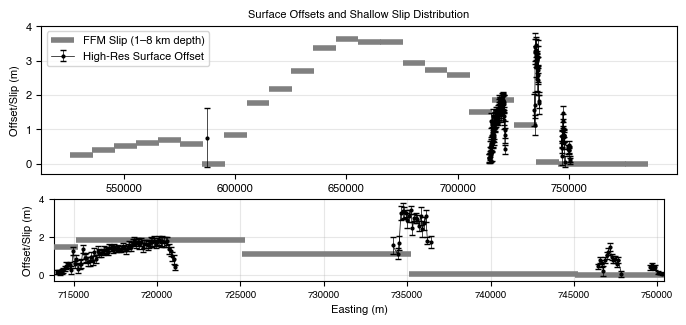

In [34]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

# inset for non-Morón profiles
axins = ax.inset_axes(
    [0.02, -0.72, 0.96, 0.55],
)

xmin_zoom = np.inf
xmax_zoom = -np.inf

for file in erf_files:

    erf = pd.read_csv(file)

    if "Moron" in file:

        erf["geometry"] = gpd.points_from_xy(erf["x"], erf["y"])
        erf = gpd.GeoDataFrame(erf, geometry="geometry", crs=crs)

        ax.errorbar(
            erf.geometry.x,
            -erf["par_total_offset"],
            yerr=erf["par_fit_sig"],
            fmt="o-",
            ms=2,
            lw=0.5,
            capsize=2,
            color="black",
            zorder=12,
            label='High-Res Surface Offset'
        )

    else:

        erf["geometry"] = erf["geometry"].apply(wkt.loads)
        erf = gpd.GeoDataFrame(erf, geometry="geometry", crs=crs)

        # Main plot
        ax.errorbar(
            erf.geometry.x,
            -erf["par_total_offset"],
            yerr=erf["par_fit_sig"],
            fmt="o-",
            ms=2,
            lw=0.5,
            capsize=2,
            color="black",
            zorder=12,
        )

        # Inset plot
        axins.errorbar(
            erf.geometry.x,
            -erf["par_total_offset"],
            yerr=erf["par_fit_sig"],
            fmt="o-",
            ms=2,
            lw=0.5,
            capsize=2,
            color="black",
            zorder=12,
        )

        xmin_zoom = min(xmin_zoom, erf.geometry.x.min())
        xmax_zoom = max(xmax_zoom, erf.geometry.x.max())

# ----------------------------------------------------------
# Plot FFM horizontal bars
# ----------------------------------------------------------

for i, (_, row) in enumerate(surface.iterrows()):

    if i == 0:
        ax.hlines(
            y=row["slip"],
            xmin=row["xmin"],
            xmax=row["xmax"],
            linewidth=4,
            color="grey",
            zorder=10,
            label="FFM Slip (1–8 km depth)",
        )
    else:
        ax.hlines(
            y=row["slip"],
            xmin=row["xmin"],
            xmax=row["xmax"],
            linewidth=4,
            color="grey",
            zorder=10,
        )

    # Also draw on inset
    axins.hlines(
        y=row["slip"],
        xmin=row["xmin"],
        xmax=row["xmax"],
        linewidth=4,
        color="grey",
        zorder=10,
    )

# ----------------------------------------------------------
# Zoom limits
# ----------------------------------------------------------

pad = 150  # meters

axins.set_xlim(xmin_zoom - pad, xmax_zoom + pad)

# Match the y-range of the main plot
axins.set_ylim(ax.get_ylim())

# Styling
axins.grid(alpha=0.3)
axins.tick_params(labelsize=7)

# Draw zoom box and connectors
#mark_inset(
#    ax,
#    axins,
#    loc1=1,
#    loc2=2,
#    fc="none",
#    ec="0.4",
#    lw=0.8,
#)

# ----------------------------------------------------------
# Finish figure
# ----------------------------------------------------------

ax.legend()

axins.set_xlabel("Easting (m)")
ax.set_ylabel("Offset/Slip (m)")
axins.set_ylabel("Offset/Slip (m)")
ax.set_title("Surface Offsets and Shallow Slip Distribution")

ax.grid(alpha=0.3,axis='y')
plt.tight_layout()

fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/FullSurfaceSlipDistributionWInset.pdf',dpi=300,transparent=True)
plt.show()


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


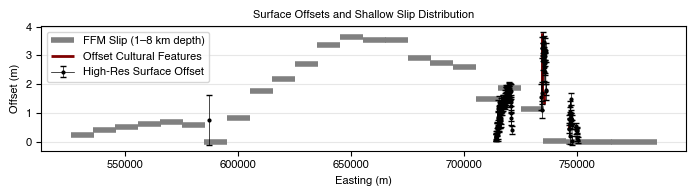

In [35]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 2))

for file in erf_files:

    erf = pd.read_csv(file)

    if "Moron" in file:

        erf["geometry"] = gpd.points_from_xy(erf["x"], erf["y"])
        erf = gpd.GeoDataFrame(erf, geometry="geometry", crs=crs)

        ax.errorbar(
            erf.geometry.x,
            -erf["par_total_offset"],
            yerr=erf["par_fit_sig"],
            fmt="o-",
            ms=2,
            lw=0.5,
            capsize=2,
            color="black",
            zorder=12,
            label='High-Res Surface Offset'
        )

    else:

        erf["geometry"] = erf["geometry"].apply(wkt.loads)
        erf = gpd.GeoDataFrame(erf, geometry="geometry", crs=crs)

        # Main plot
        ax.errorbar(
            erf.geometry.x,
            -erf["par_total_offset"],
            yerr=erf["par_fit_sig"],
            fmt="o-",
            ms=2,
            lw=0.5,
            capsize=2,
            color="black",
            zorder=12,
        )

# ----------------------------------------------------------
# Plot FFM horizontal bars
# ----------------------------------------------------------

for i, (_, row) in enumerate(surface.iterrows()):

    if i == 0:
        ax.hlines(
            y=row["slip"],
            xmin=row["xmin"],
            xmax=row["xmax"],
            linewidth=4,
            color="grey",
            zorder=10,
            label="FFM Slip (1–8 km depth)",
        )
    else:
        ax.hlines(
            y=row["slip"],
            xmin=row["xmin"],
            xmax=row["xmax"],
            linewidth=4,
            color="grey",
            zorder=10,
        )
## Plot offset features
for i in range(len(offset_pts)):
    if i == 0:
        ax.vlines(x=offset_pts.easting.iloc[i],linewidth=2,
           ymin=offset_pts['min'].iloc[i],ymax=offset_pts['max'].iloc[i],
           color='maroon',zorder=11,label='Offset Cultural Features')
    ax.vlines(x=offset_pts.easting.iloc[i],linewidth=2,
           ymin=offset_pts['min'].iloc[i],ymax=offset_pts['max'].iloc[i]+0.01,
           color='maroon',zorder=11)
# ----------------------------------------------------------
# Finish figure
# ----------------------------------------------------------

ax.legend()

ax.set_ylabel("Offset (m)")
ax.set_xlabel('Easting (m)')
ax.set_title("Surface Offsets and Shallow Slip Distribution")

ax.grid(alpha=0.3,axis='y')
plt.tight_layout()

fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/FullSurfaceSlipDistribution.pdf',dpi=300,transparent=True)
plt.show()

### Each Point

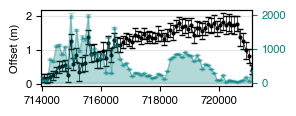

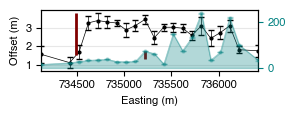

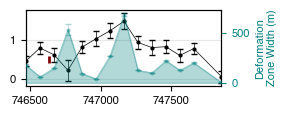

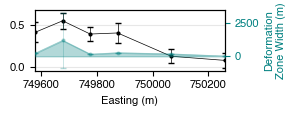

In [36]:
erf_files = [#'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar 25_ProfLen2000_SwathWidth50_every0.4m.csv',
    #'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar AS_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_caraballeda_ProfLen2000_SwathWidth50_every0.4m.csv',
    #'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Moron_ProfLen15000_SwathWidth500_every10m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m.csv']

region = [laguaira,caraballeda,naiguata,camuri]
names = ['CatiaLaMar','caraballeda','Naiguata','CamuriGrande']
for name,file,reg in zip(names,erf_files,region):
    fig, ax = plt.subplots(figsize=(3, 1.2))

    erf = pd.read_csv(file)   
    erf["geometry"] = erf["geometry"].apply(wkt.loads)
    erf = gpd.GeoDataFrame(erf,geometry="geometry",crs=crs)
    ax.errorbar(
            erf.geometry.x,
            -1*erf['par_total_offset'],
            yerr=erf['par_fit_sig'],#+erf['par_total_offset_sig'],
            fmt='o-',
            ms=2,
            lw=0.5,
            capsize=2,
            color='black',
            zorder=2
        )
    
    ax2 = ax.twinx()
    ax2.errorbar(
            erf.geometry.x,
            erf['par_shear_width']*4,
            yerr=erf['par_shear_width_sig']*4,
            fmt='o-',
            ms=2,
            lw=0.5,
            capsize=2,
            color='teal',
            alpha=0.3,
            zorder=5
        )
    ax2.fill_between(erf.geometry.x,
                     erf['par_shear_width']*4,
                     np.zeros(len(erf)),
                     color='teal',
                    alpha=0.3,zorder=5)
    
    ## Plot offset features
    pts = offset_pts[(offset_pts.easting >erf.geometry.x.min()) & (offset_pts.easting < erf.geometry.x.max())]
    for i in range(len(pts)):
        ax.vlines(x=pts.easting.iloc[i],linewidth=2,
               ymin=pts['min'].iloc[i],ymax=pts['max'].iloc[i]+0.01,
               color='maroon',zorder=11)
        
    if name.__contains__('Camuri') or name.__contains__('caraballeda'):
        ax.set_xlabel("Easting (m)")
    if name.__contains__('Catia') or name.__contains__('caraballeda'):
        ax.set_ylabel("Offset (m)")
    if name.__contains__('Naiguata') or name.__contains__('Camuri'):
        ax2.set_ylabel("Deformation\nZone Width (m)", color='teal')
    ax2.tick_params(axis='y', colors='teal')
    #ax.set_title("Across-fault Surface Displacement and Deformation Zone Width")
    ax.set_xlim(erf.geometry.x.min(), erf.geometry.x.max())
    ax.grid(alpha=0.3,axis='y')
    ax.margins(x=0)
    ax2.margins(x=0)
    plt.tight_layout()
    fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/DefoMapParts/{name}SurfaceSlipDistribution.png',dpi=300,transparent=True)
   
    plt.show()

## Broad deformation and afterslip at the airport

/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/pygmt/helpers/decorators.py:833: RuntimeWarning: Input image has dtype: float32 which is unsupported, and may result in an incorrect output. Please recast image to a uint8 dtype and/or scale to 0-255 range, e.g. using a histogram equalization function like skimage.exposure.equalize_hist.
  return module_func(*args, **kwargs)


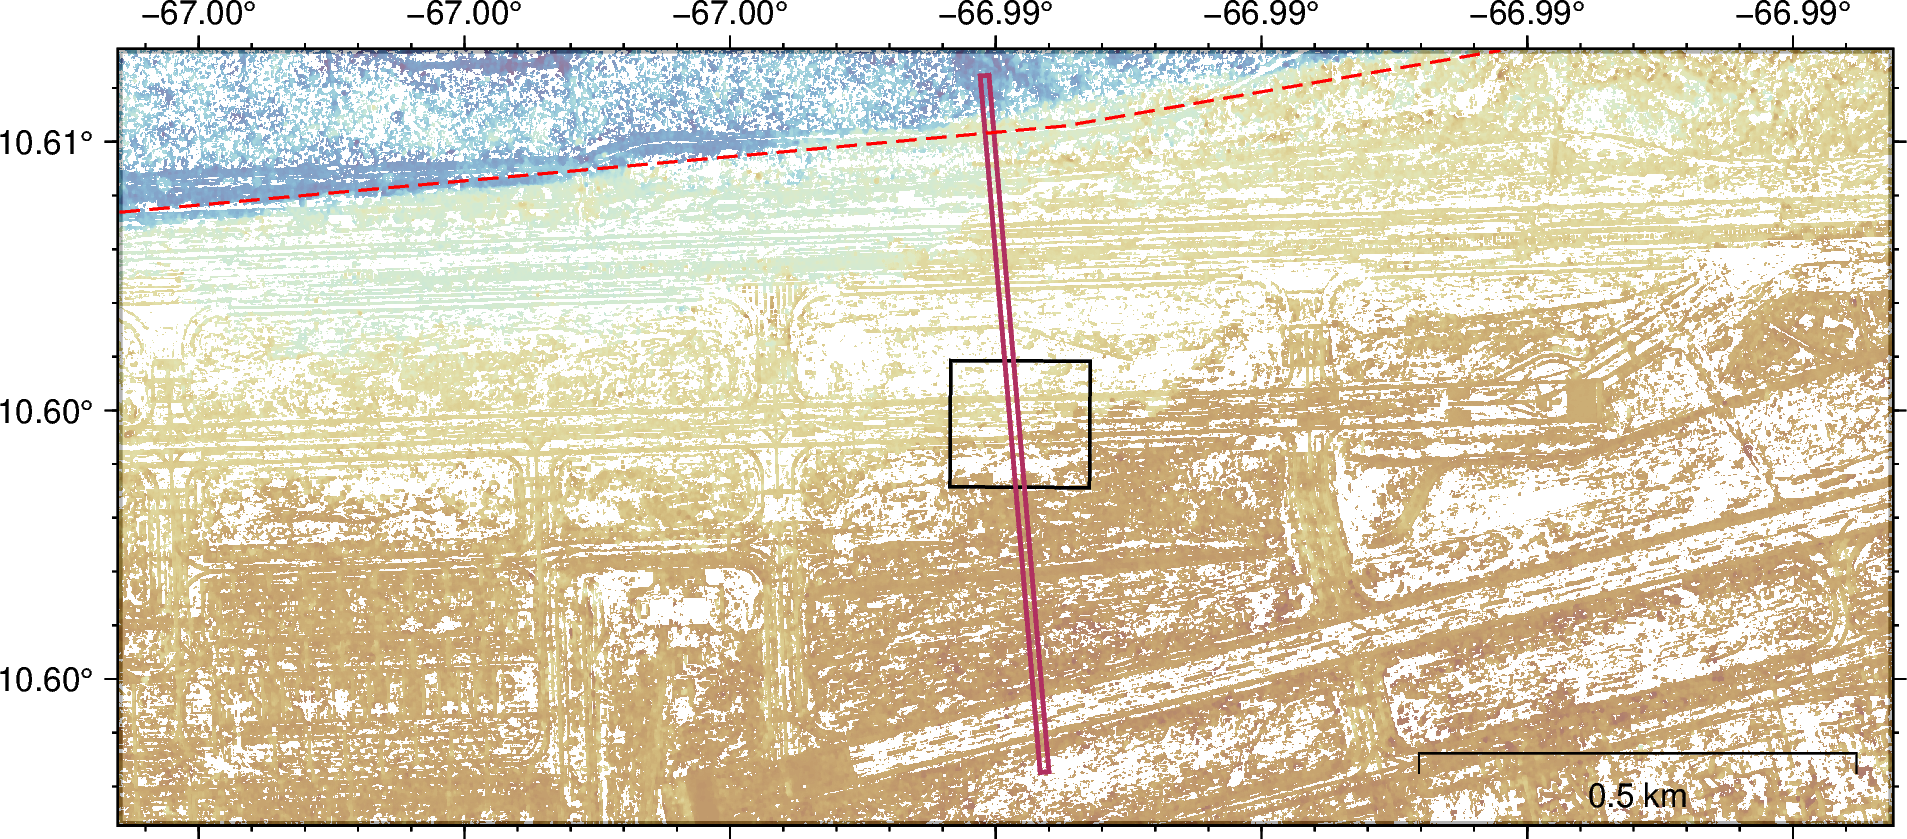

In [55]:
im = rioxarray.open_rasterio('/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_CatiaLaMar.tif')
im = im.rio.reproject("EPSG:4326")
# map

width,name,reg = 15,'afterslip_region', [-67.003603, -66.985082,10.5985,10.6065]
    # Introductory figure base
fig = pygmt.Figure()
# Configuration for the 'current figure'.
pygmt.config(MAP_FRAME_TYPE="plain")
pygmt.config(FORMAT_GEO_MAP="ddd.xx")
pygmt.config(FONT_ANNOT_PRIMARY="8p")
pygmt.config(FONT_ANNOT_SECONDARY="8p")
# Plot the base map of the main figure. 
fig.basemap(region=reg, projection=f"M{width}c", frame=["WNse", "af"])
#fig.coast(water='skyblue3')
# Imagery
pygmt.makecpt(cmap='SCM/romaO',series=[-1,2],background='o')
fig.grdimage(grid=im,cmap=True,transparency=30)
box = '/Volumes/Venezuela/Venezuela2026Doublet/GIS/Square.shp'
fig.plot(box,pen='0.7p,black')
swath = '/Volumes/Venezuela/Venezuela2026Doublet/GIS/AirportSwath.geojson'
swath_gdf = gpd.read_file(swath).to_crs('EPSG:4326')
fig.plot(swath_gdf,pen='1p,maroon')
fig.plot(data=simple_trace, pen="0.6p,red,-")
fig.basemap(map_scale='JBR+w0.5k+o-4c/-0.6c+lkm')
fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/Deformation_{name}.pdf',dpi=300)
fig.show()

In [13]:
crs = 'EPSG:32619'

swath_dict = {
    'T1':{'swath_az':85, 
             'fault_az':85,
             'swath_width':10,
             'swath_length':800,
             'resolution':0.4,
             'x':[719435.7],
             'y':[1172859.1],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toLG1_20260405_20260625_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toLG1_20260405_20260625_NS_CatiaLaMar.tif'},
    'T2':{'swath_az':85, 
             'fault_az':85,
             'swath_width':10,
             'swath_length':800,
             'resolution':0.4,
             'x':[719435.7],
             'y':[1172859.1],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_NS_CatiaLaMar.tif'},
    'Afterslip':{'swath_az':85, 
             'fault_az':85,
             'swath_width':10,
             'swath_length':800,
             'resolution':0.4,
             'x':[719435.7],
             'y':[1172859.1],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/LG1toWV3_20260625_20260626_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/LG1toWV3_20260625_20260626_NS_CatiaLaMar.tif'}}

points_dfs = []
samps_dfs = []

for key in list(swath_dict.keys()):
    print(key)
    # Read the rasters
    ns = rasterio.open(swath_dict[key]['nsfile'],masked=True)
    ew = rasterio.open(swath_dict[key]['ewfile'],masked=True)

    xs = swath_dict[key]['x']
    ys = swath_dict[key]['y']

    for i in range(len(xs)):
    
        df = pd.DataFrame({'x':xs,
                           'y':ys})
        df["region"] = key

        x0, y0 = xs[i], ys[i]
    
        ns_samps, spts, dists = tt.sample_swath(
            ns, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ns_samps[ns_samps == -9999] = np.nan
    
        ew_samps, spts, dists = tt.sample_swath(
            ew, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ew_samps[ew_samps == -9999] = np.nan
    
        par, perp = tt.projectParPerp(
            ns_samps - np.nanmean(ns_samps),
            ew_samps - np.nanmean(ew_samps),
            swath_dict[key]['fault_az']
        )

        tdf = pd.DataFrame({'dists':dists,'par':par,'perp':perp,'x':spts[:,0],'y':spts[:,1]})

        (
            par_intercept,
            par_total_offset,
            par_fault_loc,
            par_shear_width,
            par_total_offset_sig,
            par_fault_loc_sig,
            par_shear_width_sig,
            par_slope1,
            par_slope1_sig,
            par_slope2,
            par_slope2_sig,
            par_fzw_offset,
            par_ep_offset,
            par_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(par, dists)
    
        par_fit_sig = np.nanstd(
            par
            - tt.erf_function_twoslope(
                dists,
                par_intercept,
                par_total_offset,
                par_fault_loc,
                par_shear_width,
                par_slope1,
                par_slope2,
            )
        )
        df.loc[i, "par_intercept"] = par_intercept
        df.loc[i, "par_total_offset"] = par_total_offset
        df.loc[i, "par_fault_loc"] = par_fault_loc
        df.loc[i, "par_shear_width"] = par_shear_width
        df.loc[i, "par_total_offset_sig"] = par_total_offset_sig
        df.loc[i, "par_fault_loc_sig"] = par_fault_loc_sig
        df.loc[i, "par_shear_width_sig"] = par_shear_width_sig
        df.loc[i, "par_slope1"] = par_slope1
        df.loc[i, "par_slope1_sig"] = par_slope1_sig
        df.loc[i, "par_slope2"] = par_slope2
        df.loc[i, "par_slope2_sig"] = par_slope2_sig
        df.loc[i, "par_fzw_offset"] = par_fzw_offset
        df.loc[i, "par_ep_offset"] = par_ep_offset
        df.loc[i, "par_fit_sig"] = par_fit_sig
        
        (
        perp_intercept,
        perp_total_offset,
        perp_fault_loc,
        perp_shear_width,
        perp_total_offset_sig,
        perp_fault_loc_sig,
        perp_shear_width_sig,
        perp_slope1,
        perp_slope1_sig,
        perp_slope2,
        perp_slope2_sig,
        perp_fzw_offset,
        perp_ep_offset,
        perp_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(perp, dists)

        perp_fit_sig = np.nanstd(
            perp
            - tt.erf_function_twoslope(
                dists,
                perp_intercept,
                perp_total_offset,
                perp_fault_loc,
                perp_shear_width,
                perp_slope1,
                perp_slope2,
            )
        )

        df.loc[i, "perp_intercept"] = perp_intercept
        df.loc[i, "perp_total_offset"] = perp_total_offset
        df.loc[i, "perp_fault_loc"] = perp_fault_loc
        df.loc[i, "perp_shear_width"] = perp_shear_width
        df.loc[i, "perp_total_offset_sig"] = perp_total_offset_sig
        df.loc[i, "perp_fault_loc_sig"] = perp_fault_loc_sig
        df.loc[i, "perp_shear_width_sig"] = perp_shear_width_sig
        df.loc[i, "perp_slope1"] = perp_slope1
        df.loc[i, "perp_slope1_sig"] = perp_slope1_sig
        df.loc[i, "perp_slope2"] = perp_slope2
        df.loc[i, "perp_slope2_sig"] = perp_slope2_sig
        df.loc[i, "perp_fzw_offset"] = perp_fzw_offset
        df.loc[i, "perp_ep_offset"] = perp_ep_offset
        df.loc[i, "perp_fit_sig"] = perp_fit_sig

    points_dfs.append(df)
    samps_dfs.append(tdf)

T1
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-2.21951822100933), np.float64(-399.7999999999773), 0, np.float64(-0.00027757856690963686), np.float64(-0.00027757856690963686)), (inf, np.float64(2.21951822100933), np.float64(399.7999999999773), np.float64(199.89999999998864), np.float64(0.00027757856690963686), np.float64(0.00027757856690963686)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-1.099562317123924), np.float64(-399.79999999

/var/folders/cl/y9nzvjr51wjdfxvfj59yzn400000gp/T/ipykernel_82704/928415245.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


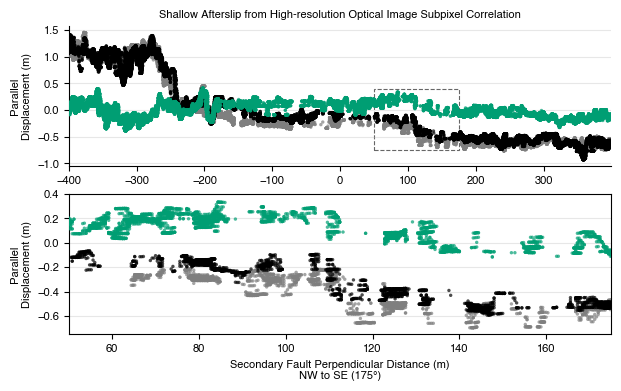

In [61]:
from matplotlib.patches import Rectangle
from matplotlib.patches import ConnectionPatch

labels = swath_dict.keys()

colors = [
    "#7f7f7f",   # gray
    "#000000",   # black
    "#009E73",   # green
]

# Much more compact than before
fig, (ax, axins) = plt.subplots(
    2, 1,
    figsize=(7, 4),
    gridspec_kw={"height_ratios": [1, 1], "hspace": 0.2},
)

# -------------------------------------------------------
# Plot both panels
# -------------------------------------------------------
for df, label, color in zip(samps_dfs, labels, colors):

    df = df.sort_values("dists")
    y = df.par #- df.par.mean()

    # Main panel
    ax.scatter(
        df.dists,
        y,
        s=6,
        color=color,
        alpha=0.7,
        edgecolors="none",
        rasterized=True,
        label=label,zorder=22
    )

    # Zoom panel
    axins.scatter(
        df.dists,
        y,
        s=6,
        color=color,
        alpha=0.7,
        edgecolors="none",
        rasterized=True,zorder=22
    )
axins.set_ylim(-0.75,0.4)
# -------------------------------------------------------
# Zoom limits
# -------------------------------------------------------
xmin, xmax = 50, 175

axins.set_xlim(xmin, xmax)

# -------------------------------------------------------
# Draw zoom box on main panel
# -------------------------------------------------------
y0, y1 = axins.get_ylim()

rect = Rectangle(
    (xmin, y0),
    xmax - xmin,
    y1 - y0,
    facecolor="none",
    edgecolor="0.4",
    linestyle="--",
    linewidth=0.8,
)

ax.add_patch(rect)

# -------------------------------------------------------
# Formatting
# -------------------------------------------------------
ax.set_title("Shallow Afterslip from High-resolution Optical Image Subpixel Correlation")

ax.set_ylabel("Parallel\nDisplacement (m)")
axins.set_ylabel("Parallel\nDisplacement (m)")
axins.set_xlabel("Secondary Fault Perpendicular Distance (m)\nNW to SE (175°)")

ax.grid(axis="y", alpha=0.3)
axins.grid(axis="y", alpha=0.3)

ax.margins(x=0)
axins.margins(x=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    "/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/AfterslipProfileExtended.png",
    dpi=300,
    transparent=True,bbox_inches="tight"
)

plt.show()

## Strain

In [3]:
# rho*g*h
1400*9.81*50/1e6 # kg/m3, m/s2, m = kg/m/s2 = N


0.6867

In [4]:
from scipy.optimize import curve_fit

def strain_from_erf_twoslope(dists,par_intercept, par_total_offset, par_fault_loc,
                    par_shear_width, par_slope1, par_slope2):
    z = (dists-par_fault_loc)/(par_shear_width*np.sqrt(2))
    strain = par_total_offset/(par_shear_width*np.sqrt(2*np.pi))*np.exp(-z**2)+par_slope1+par_slope2
    return strain

def atan_interseismic_locking_depth(dists, par_total_offset, d):
    return par_total_offset/np.pi*np.atan(dists/d)

def depth_to_elastic_slip(dists, par_intercept, par_total_offset, par_fault_loc,
                          par_shear_width):
    dists = dists - dists.mean()
    disp = tt.erf_function_noslope(
        dists,
        par_intercept,
        par_total_offset,
        par_fault_loc,
        par_shear_width
    )

    # Fit only d
    fit_func = lambda x, d: atan_interseismic_locking_depth(
        x,
        par_total_offset,
        d
    )

    popt, pcov = curve_fit(
        fit_func,
        dists,
        disp,
        p0=[10]   # initial locking depth estimate
    )

    d = popt[0]

    return d

In [5]:
0.2/(1.03)

0.1941747572815534

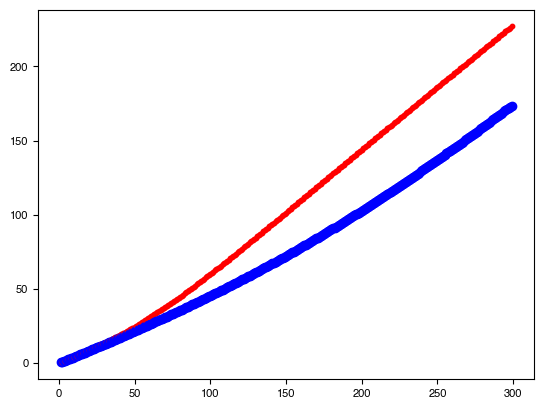

In [6]:
dists = np.arange(0,1000)
dists2 = np.arange(0,300)
widths = np.arange(1,300)
plt.figure()
for i, width in enumerate(widths):
    d = depth_to_elastic_slip(dists, 0, 2, 0,width)
    d2 = depth_to_elastic_slip(dists2, 0, 10, 0, width)
    plt.scatter(width,d,color='blue')
    plt.scatter(width,d2,color='red',s=10)
plt.show()


In [7]:
600/8

75.0

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


Morón
Catia La Mar
Caraballeda
Naiguatá
Camurí Grande


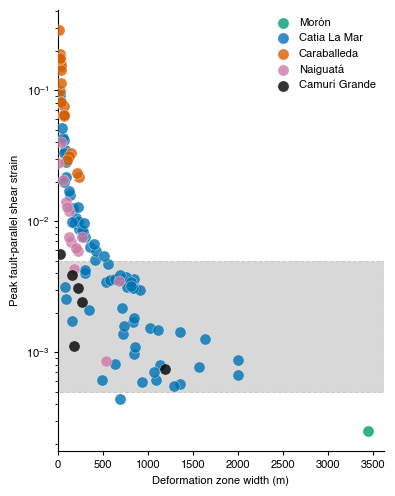

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import LogLocator
# ============================================================
# Data
# ============================================================

erf_files = [
        '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Moron_ProfLen15000_SwathWidth500_every10m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Catia La Mar_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Caraballeda_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Naiguata_ProfLen2000_SwathWidth50_every0.4m.csv',
    '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Camuri Grande_ProfLen2000_SwathWidth50_every0.4m.csv'
]

names = [
        'Morón',
    'Catia La Mar',
    'Caraballeda',
    'Naiguatá',
    'Camurí Grande'
]

# Colorblind-safe palette
colors = [
        "#009E73",
    "#0072B2",
    "#D55E00",
    "#CC79A7",
    "#000000"
]

# ============================================================
# Figure
# ============================================================

fig, ax = plt.subplots(figsize=(4, 5))

dists = np.arange(-500,500, 1)

for name, file, color in zip(names, erf_files, colors):

    df = pd.read_csv(file)

    peak_shear = []
    depths = []

    for _, row in df.iterrows():

        strain = strain_from_erf_twoslope(
            dists,
            row.par_intercept,
            -row.par_total_offset,
            row.par_fault_loc,
            row.par_shear_width,
            row.par_slope1,
            row.par_slope2
        )

        peak_shear.append(np.nanmax(strain))

    df["peak_shear_strain"] = peak_shear    

    ax.scatter(
        df.par_shear_width*4,#
        df.peak_shear_strain,
        s=65,
        color=color,
        edgecolor='white',
        linewidth=0.3,
        alpha=0.8,
        rasterized=True,
        label=name,
        zorder=3
    )

    # Locate airport cracks
    print(name)
    locate_dots = False
    if locate_dots == True:
        if name == "Catia La Mar":
            print(name)
            target_easting = 719429

            idx = (df["easting"] - target_easting).abs().idxmin()
            airport = df.loc[idx]

            ax.axvline(
                airport["par_shear_width"] * 4,
                color=color,
                linestyle='--',
                linewidth=1.2,
                zorder=2,
            )
        if name == "Caraballeda":
            print(name)
            target_easting = 734425

            idx = (df["easting"] - target_easting).abs().idxmin()
            airport = df.loc[idx]

            print(airport)

            ax.scatter(
            airport.par_shear_width*4,#
            airport.peak_shear_strain,
            s=75,
            color='red',
            edgecolor='white',
            linewidth=0.3,
            alpha=0.8,
            rasterized=True,
            label=name,
            zorder=3
        )
# ============================================================
# Reference lines
# ============================================================

ax.axhspan(0.005,0.0005,
    color='0.5',
    linestyle='--',
    linewidth=0.8,
    zorder=1,
    alpha=0.3)

# ============================================================
# Axes
# ============================================================

ax.set_yscale('log')

ax.set_xlabel('Deformation zone width (m)')
ax.set_ylabel('Peak fault-parallel shear strain')

ax.set_xlim(left=0)
#ax.set_ylim(2e-4, 5e-2)

ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(2,10)*0.1)
)

# ============================================================
# Appearance
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(
    which='major',
    direction='out',
    length=3,
    width=0.8
)

ax.tick_params(
    which='minor',
    direction='out',
    length=2,
    width=0.6
)

ax.legend(
    frameon=False,
    loc='upper right',
    handletextpad=0.4,
    borderpad=0.2
)


fig.tight_layout()

plt.savefig(
    f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Strain/StrainFigureScatterPlot.pdf',
    dpi=300,
    bbox_inches='tight', transparent=True
)

plt.show()


In [ ]:
depth

np.float64(7.493237853461685)

## Figure X. Afterslip at the airport

In [ ]:
im = rioxarray.open_rasterio('/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_CatiaLaMar.tif')
im = im.rio.reproject("EPSG:4326")
imOrtho = rioxarray.open_rasterio('/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/mm26JUN26150940CatiaLaMar_Interpolated.tif')
imOrtho = imOrtho.rio.reproject("EPSG:4326")

'epsg:32619'

In [ ]:
# map

width,name,reg = 15,'afterslip_region', [-67.003, -66.985,10.6000033,10.6059895]
    # Introductory figure base
fig = pygmt.Figure()
# Configuration for the 'current figure'.
pygmt.config(MAP_FRAME_TYPE="plain")
pygmt.config(FORMAT_GEO_MAP="ddd.xx")
pygmt.config(FONT_ANNOT_PRIMARY="8p")
pygmt.config(FONT_ANNOT_SECONDARY="8p")
# Plot the base map of the main figure. 
fig.basemap(region=reg, projection=f"M{width}c", frame=["WNse", "af"])
#fig.coast(water='skyblue3')
# Imagery
pygmt.makecpt(cmap="gray", series=[-170,3000])
fig.grdimage(grid=imOrtho, cmap=True)
pygmt.makecpt(cmap='SCM/romaO',series=[-1,2],background='o')
fig.grdimage(grid=im,cmap=True,transparency=30)
box = '/Volumes/Venezuela/Venezuela2026Doublet/GIS/Square.shp'
fig.plot(box,pen='0.7p,black')
swath = '/Volumes/Venezuela/Venezuela2026Doublet/GIS/AirportSwath.geojson'
swath_gdf = gpd.read_file(swath).to_crs('EPSG:4326')
fig.plot(swath_gdf,pen='1p,maroon')
fig.plot(data=simple_trace, pen="0.6p,red,-")
fig.basemap(map_scale='JBR+w0.5k+o-4c/-0.6c+lkm')
fig.savefig(f'/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/Deformation_{name}.pdf',dpi=300)
fig.show()

NameError: name 'imOrtho' is not defined

In [ ]:
crs = 'EPSG:32619'

swath_dict = {
    'T1':{'swath_az':86,
             'fault_az':86,
             'swath_width':5,
             'swath_length':300,
             'resolution':0.4,
             'x':[719446.33],
             'y':[1172750.47],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toLG1_20260405_20260625_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toLG1_20260405_20260625_NS_CatiaLaMar.tif'},
    'T2':{'swath_az':86,
             'fault_az':86,
             'swath_width':5,
             'swath_length':300,
             'resolution':0.4,
             'x':[719446.33],
             'y':[1172750.47],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_NS_CatiaLaMar.tif'},
    'Afterslip':{'swath_az':86,
             'fault_az':86,
             'swath_width':5,
             'swath_length':300,
             'resolution':0.4,
             'x':[719446.33],
             'y':[1172750.47],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/LG1toWV3_20260625_20260626_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/LG1toWV3_20260625_20260626_NS_CatiaLaMar.tif'}}

points_dfs = []
samps_dfs = []

for key in list(swath_dict.keys()):
    print(key)
    # Read the rasters
    ns = rasterio.open(swath_dict[key]['nsfile'],masked=True)
    ew = rasterio.open(swath_dict[key]['ewfile'],masked=True)

    xs = swath_dict[key]['x']
    ys = swath_dict[key]['y']

    for i in range(len(xs)):
    
        df = pd.DataFrame({'x':xs,
                           'y':ys})
        df["region"] = key

        x0, y0 = xs[i], ys[i]
    
        ns_samps, spts, dists = tt.sample_swath(
            ns, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ns_samps[ns_samps == -9999] = np.nan
    
        ew_samps, spts, dists = tt.sample_swath(
            ew, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ew_samps[ew_samps == -9999] = np.nan
    
        par, perp = tt.projectParPerp(
            ns_samps - np.nanmean(ns_samps),
            ew_samps - np.nanmean(ew_samps),
            swath_dict[key]['fault_az']
        )

        tdf = pd.DataFrame({'dists':dists,'par':par,'perp':perp,'x':spts[:,0],'y':spts[:,1]})

        (
            par_intercept,
            par_total_offset,
            par_fault_loc,
            par_shear_width,
            par_total_offset_sig,
            par_fault_loc_sig,
            par_shear_width_sig,
            par_slope1,
            par_slope1_sig,
            par_slope2,
            par_slope2_sig,
            par_fzw_offset,
            par_ep_offset,
            par_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(par, dists)
    
        par_fit_sig = np.nanstd(
            par
            - tt.erf_function_twoslope(
                dists,
                par_intercept,
                par_total_offset,
                par_fault_loc,
                par_shear_width,
                par_slope1,
                par_slope2,
            )
        )
        df.loc[i, "par_intercept"] = par_intercept
        df.loc[i, "par_total_offset"] = par_total_offset
        df.loc[i, "par_fault_loc"] = par_fault_loc
        df.loc[i, "par_shear_width"] = par_shear_width
        df.loc[i, "par_total_offset_sig"] = par_total_offset_sig
        df.loc[i, "par_fault_loc_sig"] = par_fault_loc_sig
        df.loc[i, "par_shear_width_sig"] = par_shear_width_sig
        df.loc[i, "par_slope1"] = par_slope1
        df.loc[i, "par_slope1_sig"] = par_slope1_sig
        df.loc[i, "par_slope2"] = par_slope2
        df.loc[i, "par_slope2_sig"] = par_slope2_sig
        df.loc[i, "par_fzw_offset"] = par_fzw_offset
        df.loc[i, "par_ep_offset"] = par_ep_offset
        df.loc[i, "par_fit_sig"] = par_fit_sig
        
        (
        perp_intercept,
        perp_total_offset,
        perp_fault_loc,
        perp_shear_width,
        perp_total_offset_sig,
        perp_fault_loc_sig,
        perp_shear_width_sig,
        perp_slope1,
        perp_slope1_sig,
        perp_slope2,
        perp_slope2_sig,
        perp_fzw_offset,
        perp_ep_offset,
        perp_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(perp, dists)

        perp_fit_sig = np.nanstd(
            perp
            - tt.erf_function_twoslope(
                dists,
                perp_intercept,
                perp_total_offset,
                perp_fault_loc,
                perp_shear_width,
                perp_slope1,
                perp_slope2,
            )
        )

        df.loc[i, "perp_intercept"] = perp_intercept
        df.loc[i, "perp_total_offset"] = perp_total_offset
        df.loc[i, "perp_fault_loc"] = perp_fault_loc
        df.loc[i, "perp_shear_width"] = perp_shear_width
        df.loc[i, "perp_total_offset_sig"] = perp_total_offset_sig
        df.loc[i, "perp_fault_loc_sig"] = perp_fault_loc_sig
        df.loc[i, "perp_shear_width_sig"] = perp_shear_width_sig
        df.loc[i, "perp_slope1"] = perp_slope1
        df.loc[i, "perp_slope1_sig"] = perp_slope1_sig
        df.loc[i, "perp_slope2"] = perp_slope2
        df.loc[i, "perp_slope2_sig"] = perp_slope2_sig
        df.loc[i, "perp_fzw_offset"] = perp_fzw_offset
        df.loc[i, "perp_ep_offset"] = perp_ep_offset
        df.loc[i, "perp_fit_sig"] = perp_fit_sig

    points_dfs.append(df)
    samps_dfs.append(tdf)

T1
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-0.5201284316765091), np.float64(-149.80000000000211), 0, np.float64(-0.00017360762071979365), np.float64(-0.00017360762071979365)), (inf, np.float64(0.5201284316765091), np.float64(149.80000000000211), np.float64(74.90000000000106), np.float64(0.00017360762071979365), np.float64(0.00017360762071979365)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-0.7637292459182008), np.float64(-149.80

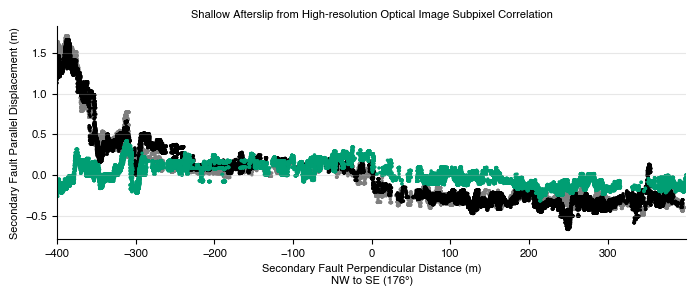

In [ ]:
labels = swath_dict.keys()

colors = [
    "#7f7f7f",   # gray
    "#000000",   # black
    "#009E73",   # green
]

fig, ax = plt.subplots(figsize=(7, 3))

for df, label, color in zip(samps_dfs, labels, colors):

    df = df.sort_values("dists")

    ax.scatter(
        df.dists,
        df.par - df.par.mean(),
        s=6,
        color=color,
        edgecolors="none",
        rasterized=True,   # keeps vector PDFs small
        label=label,
    )
ax.set_title('Shallow Afterslip from High-resolution Optical Image Subpixel Correlation')
ax.set_xlabel("Secondary Fault Perpendicular Distance (m)\nNW to SE (176°)")
ax.set_ylabel("Secondary Fault Parallel Displacement (m)")

ax.grid(axis="y", alpha=0.3)
ax.margins(x=0)

#ax.legend(
#    frameon=False,
#    ncol=3,
#    loc="lower center",
#)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(
    "/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/AfterslipProfile.png",
    dpi=300,
    transparent=True,
)
plt.show()

### Without afterslip modeling

In [79]:
crs = 'EPSG:32619'

swath_dict = {
    'T1':{'swath_az':86,
             'fault_az':86,
             'swath_width':5,
             'swath_length':300,
             'resolution':0.4,
             'x':[719446.33],
             'y':[1172750.47],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toLG1_20260405_20260625_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3toLG1_20260405_20260625_NS_CatiaLaMar.tif'},
    'T2':{'swath_az':86,
             'fault_az':86,
             'swath_width':5,
             'swath_length':300,
             'resolution':0.4,
             'x':[719446.33],
             'y':[1172750.47],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/WV3_20260405_20260626_NS_CatiaLaMar.tif'},
    'Afterslip':{'swath_az':86,
             'fault_az':86,
             'swath_width':5,
             'swath_length':300,
             'resolution':0.4,
             'x':[719446.33],
             'y':[1172750.47],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/LG1toWV3_20260625_20260626_EW_CatiaLaMar.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/ForDataRelease/LG1toWV3_20260625_20260626_NS_CatiaLaMar.tif'}}

points_dfs = []
samps_dfs = []

for key in list(swath_dict.keys()):
    print(key)
    # Read the rasters
    ns = rasterio.open(swath_dict[key]['nsfile'],masked=True)
    ew = rasterio.open(swath_dict[key]['ewfile'],masked=True)

    xs = swath_dict[key]['x']
    ys = swath_dict[key]['y']

    for i in range(len(xs)):
    
        df = pd.DataFrame({'x':xs,
                           'y':ys})
        df["region"] = key

        x0, y0 = xs[i], ys[i]
    
        ns_samps, spts, dists = tt.sample_swath(
            ns, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ns_samps[ns_samps == -9999] = np.nan
    
        ew_samps, spts, dists = tt.sample_swath(
            ew, x0, y0,
            swath_dict[key]['swath_az'], swath_dict[key]['swath_length'], 
            swath_dict[key]['swath_width'], swath_dict[key]['resolution'],
            crs=crs
        )
        ew_samps[ew_samps == -9999] = np.nan
    
        par, perp = tt.projectParPerp(
            ns_samps - np.nanmean(ns_samps),
            ew_samps - np.nanmean(ew_samps),
            swath_dict[key]['fault_az']
        )

        tdf = pd.DataFrame({'dists':dists,'par':par,'perp':perp,'x':spts[:,0],'y':spts[:,1]})

        (
            par_intercept,
            par_total_offset,
            par_fault_loc,
            par_shear_width,
            par_total_offset_sig,
            par_fault_loc_sig,
            par_shear_width_sig,
            par_slope1,
            par_slope1_sig,
            par_slope2,
            par_slope2_sig,
            par_fzw_offset,
            par_ep_offset,
            par_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(par, dists)
    
        par_fit_sig = np.nanstd(
            par
            - tt.erf_function_twoslope(
                dists,
                par_intercept,
                par_total_offset,
                par_fault_loc,
                par_shear_width,
                par_slope1,
                par_slope2,
            )
        )
        df.loc[i, "par_intercept"] = par_intercept
        df.loc[i, "par_total_offset"] = par_total_offset
        df.loc[i, "par_fault_loc"] = par_fault_loc
        df.loc[i, "par_shear_width"] = par_shear_width
        df.loc[i, "par_total_offset_sig"] = par_total_offset_sig
        df.loc[i, "par_fault_loc_sig"] = par_fault_loc_sig
        df.loc[i, "par_shear_width_sig"] = par_shear_width_sig
        df.loc[i, "par_slope1"] = par_slope1
        df.loc[i, "par_slope1_sig"] = par_slope1_sig
        df.loc[i, "par_slope2"] = par_slope2
        df.loc[i, "par_slope2_sig"] = par_slope2_sig
        df.loc[i, "par_fzw_offset"] = par_fzw_offset
        df.loc[i, "par_ep_offset"] = par_ep_offset
        df.loc[i, "par_fit_sig"] = par_fit_sig
        
        (
        perp_intercept,
        perp_total_offset,
        perp_fault_loc,
        perp_shear_width,
        perp_total_offset_sig,
        perp_fault_loc_sig,
        perp_shear_width_sig,
        perp_slope1,
        perp_slope1_sig,
        perp_slope2,
        perp_slope2_sig,
        perp_fzw_offset,
        perp_ep_offset,
        perp_intercept_sig,
        ) = tt.erf_curve_fit_twoslope(perp, dists)

        perp_fit_sig = np.nanstd(
            perp
            - tt.erf_function_twoslope(
                dists,
                perp_intercept,
                perp_total_offset,
                perp_fault_loc,
                perp_shear_width,
                perp_slope1,
                perp_slope2,
            )
        )

        df.loc[i, "perp_intercept"] = perp_intercept
        df.loc[i, "perp_total_offset"] = perp_total_offset
        df.loc[i, "perp_fault_loc"] = perp_fault_loc
        df.loc[i, "perp_shear_width"] = perp_shear_width
        df.loc[i, "perp_total_offset_sig"] = perp_total_offset_sig
        df.loc[i, "perp_fault_loc_sig"] = perp_fault_loc_sig
        df.loc[i, "perp_shear_width_sig"] = perp_shear_width_sig
        df.loc[i, "perp_slope1"] = perp_slope1
        df.loc[i, "perp_slope1_sig"] = perp_slope1_sig
        df.loc[i, "perp_slope2"] = perp_slope2
        df.loc[i, "perp_slope2_sig"] = perp_slope2_sig
        df.loc[i, "perp_fzw_offset"] = perp_fzw_offset
        df.loc[i, "perp_ep_offset"] = perp_ep_offset
        df.loc[i, "perp_fit_sig"] = perp_fit_sig

    points_dfs.append(df)
    samps_dfs.append(tdf)

T1
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-0.5873773737954953), np.float64(-149.80000000000211), 0, np.float64(-0.0001960538630826058), np.float64(-0.0001960538630826058)), (inf, np.float64(0.5873773737954953), np.float64(149.80000000000211), np.float64(74.90000000000106), np.float64(0.0001960538630826058), np.float64(0.0001960538630826058)))
Returning intercept, offset at fault location, shifted fault location, 1/2 1 std shear width (4 shear width is 2 sigma 
               fault zone width), uncertainties for those parameters, then lhs slope and uncertainty, and rhs slope and uncertainty). 
               Other derived parameters are the offset at the edges of the 2 sigma shear zone, the max offset, and the endpoint offset.
               The latter two are from left to right across profile.
Bounds: Intercept, offset, fault location, 1/4 shear width, slope1, slope2
 ((-inf, np.float64(-0.5494261502540498), np.float64(-149.800000

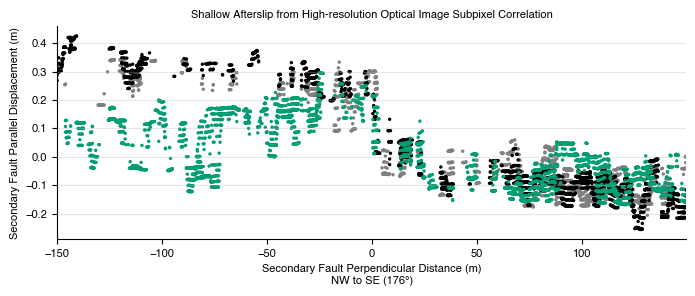

In [91]:
labels = swath_dict.keys()

colors = [
    "#7f7f7f",   # gray
    "#000000",   # black
    "#009E73",   # green
]

fig, ax = plt.subplots(figsize=(7, 3))

for df, label, color in zip(samps_dfs, labels, colors):

    df = df.sort_values("dists")

    ax.scatter(
        df.dists,
        df.par - df.par.mean(),
        s=6,
        color=color,
        edgecolors="none",
        rasterized=True,   # keeps vector PDFs small
        label=label,
    )
ax.set_title('Shallow Afterslip from High-resolution Optical Image Subpixel Correlation')
ax.set_xlabel("Secondary Fault Perpendicular Distance (m)\nNW to SE (176°)")
ax.set_ylabel("Secondary Fault Parallel Displacement (m)")

ax.grid(axis="y", alpha=0.3)
ax.margins(x=0)

#ax.legend(
#    frameon=False,
#    ncol=3,
#    loc="lower center",
#)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(
    "/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/AfterslipProfiles.png",
    dpi=300,
    transparent=True,
)
plt.show()

### With afterslip modeling

In [17]:
import sys
sys.path.append('/Users/chanagan/Documents/GitHub/tdcalc/')
import tdcalc
import matplotlib.patheffects as pe

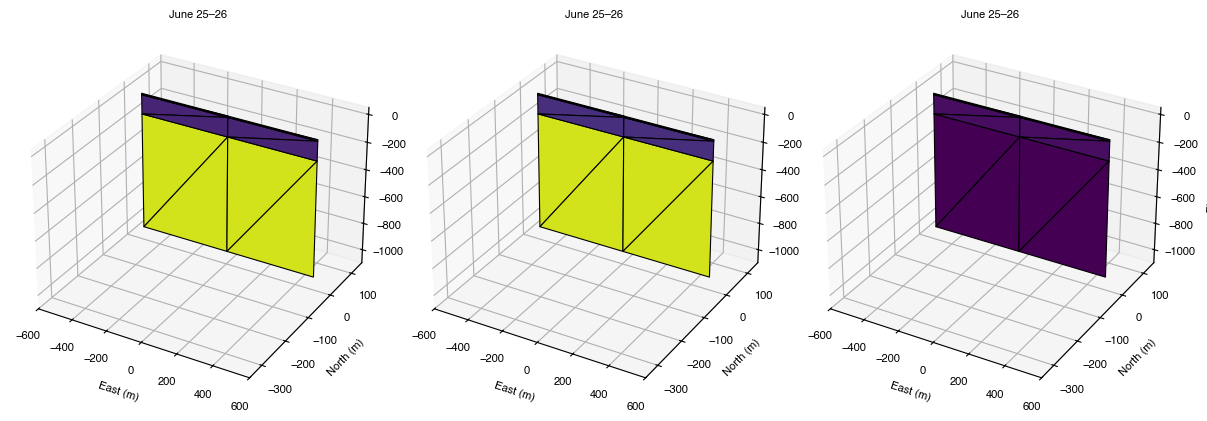

In [259]:
# Observation points and slip parameters
xs = np.zeros(301)
ys = np.linspace(-150, 150, 301)
obs = np.column_stack([xs, ys, xs])

nu = 0.25

models = {
    "Pre–June 25": {
        "slip_surface": 0.1,
        "slip_middle":0.15,
        "slip_deep": 1.4,
        "color": "grey",
        "offset": 0.1,
        "outline": "black",
    },
    "Pre–June 26": {
        "slip_surface": 0.25,
        "slip_middle":0.2,
        "slip_deep": 1.4,
        "color": "black",
        "offset": 0.1,
        "outline": "black",
    },
    "June 25–26": {
        "slip_surface": 0.15,
        "slip_middle":0.05,
        "slip_deep": 0,
        "color": "#009E73",
        "offset": 0.1,
        "outline": "black",
    }
}

# Build fault and slip, vizualise
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# =====================================================
# Fault geometry
# =====================================================

strike = 90.0      # degrees clockwise from north (90 = E-W)
dip = 90        # degrees
dip_dir = 180.0    # south

depths = np.array([0, -10, -150, -1000])

##########################################

half_length = depths[-1]/2 *-1    # along strike (m)

# fault center at surface
x_center = 0.0
y_center = 0.0

# -----------------------------------------------------
# Unit vectors
# -----------------------------------------------------

# strike direction
s = np.array([
    np.sin(np.deg2rad(strike)),
    np.cos(np.deg2rad(strike))
])

# horizontal dip direction
d = np.array([
    np.sin(np.deg2rad(dip_dir)),
    np.cos(np.deg2rad(dip_dir))
])

# horizontal offsets down dip
offsets = np.abs(depths) / np.tan(np.deg2rad(dip))

# =====================================================
# Build vertices
# =====================================================

rows = []

for depth, off in zip(depths, offsets):

    center = np.array([x_center, y_center]) + off * d

    left = center - half_length * s
    right = center + half_length * s

    rows.append([
        np.r_[left, depth],
        np.r_[center, depth],
        np.r_[right, depth],
    ])

# =====================================================
# Build triangle mesh
# =====================================================

layers = []

for i in range(len(rows)-1):

    upper = rows[i]
    lower = rows[i+1]

    tris = [

        np.array([upper[0], upper[1], lower[0]]),
        np.array([upper[1], lower[1], lower[0]]),

        np.array([upper[1], upper[2], lower[1]]),
        np.array([upper[2], lower[2], lower[1]]),

    ]

    layers.append(tris)

top_tris, middle_tris, bottom_tris = layers

# =====================================================
# Plot geometry
# =====================================================

fig = plt.figure(figsize=(12,4))

for i,(model) in enumerate(models.items()):

    ax = fig.add_subplot(1,3,i+1,projection="3d")

    slips = [model[1]["slip_surface"], model[1]["slip_middle"], model[1]["slip_deep"]]

    cmap = plt.cm.viridis
    vmax = 1.5

    for tris,slip in zip(
            [top_tris,middle_tris,bottom_tris],
            slips):

        color = cmap(slip/vmax)

        for tri in tris:

            poly = Poly3DCollection(
                [tri],
                facecolor=color,
                edgecolor='k',
                linewidth=0.8
            )

            ax.add_collection3d(poly)

    ax.set_title(name)

    ax.set_xlabel("East (m)")
    ax.set_ylabel("North (m)")
    ax.set_zlabel("Elevation (m)")

    ax.set_xlim(-600,600)
    ax.set_ylim(-350,150)
    ax.set_zlim(-1100,50)

    #ax.invert_zaxis()

plt.tight_layout()
plt.show()

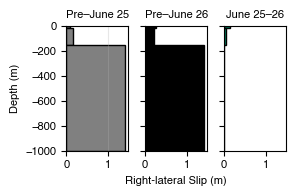

In [264]:
# Plot slip with depth
depth_edges = depths[1:]
heights = np.abs(np.diff(depths))
fig, axs = plt.subplots(nrows=1,ncols=3,figsize=(3, 2),sharey=True,sharex=True)
for i,name, model in zip(np.arange(len(models)),models.keys(),models.items()):

    slips = [model[1]["slip_surface"], model[1]["slip_middle"], model[1]["slip_deep"]]

    axs[i].barh(
        depth_edges,
        slips,
        align='edge', # bottom edge
        height=heights,
        color=model[1]["color"],
        edgecolor="black",
        label=name,
        

    )
    axs[i].set_title(name)

axs[1].set_xlabel("Right-lateral Slip (m)")
i=0
axs[i].set_ylim(depths[-1], 0)
axs[i].set_ylabel("Depth (m)")
axs[i].grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(
    "/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/ModelSlipWithDepth.png",
    dpi=300,
    transparent=True,
)
plt.show()

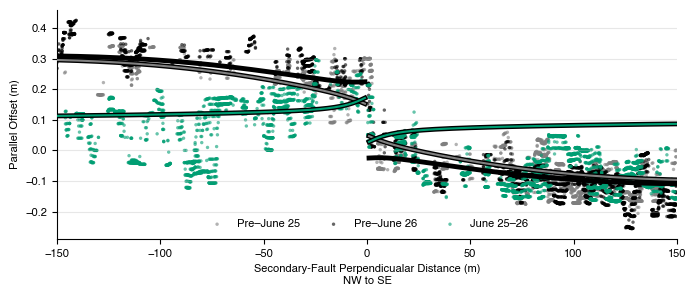

In [261]:
labels = models.keys()

colors = [
    "#7f7f7f",   # gray
    "#000000",   # black
    "#009E73",   # green
]

fig, ax = plt.subplots(figsize=(7, 3))

for df, label, color in zip(samps_dfs, labels, colors):

    df = df.sort_values("dists")

    ax.scatter(
        df.dists,
        df.par - df.par.mean(),
        s=6,
        color=color,
        alpha=0.6,
        edgecolors="none",
        rasterized=True,   # keeps vector PDFs small
        label=label,
    )
### TDCALC ###
### -------------------- TDCALC -------------------- ###

### -------------------- TDCALC -------------------- ###
for model in models.values():

    disp = np.zeros(len(obs))

    for tri in top_tris:
        disp += tdcalc.TDdispHS(
            obs,
            tri,
            [model["slip_surface"],model["slip_surface"]*0,0],
            nu,
        )[:,0]

    for tri in middle_tris:
        disp += tdcalc.TDdispHS(
            obs,
            tri,
            [model["slip_middle"],model["slip_middle"]*0,0],
            nu,
        )[:,0]

    for tri in bottom_tris:
        disp += tdcalc.TDdispHS(
            obs,
            tri,
            [model["slip_deep"],  model["slip_deep"]*0,0],
            nu,
        )[:,0]

    line, = ax.plot(
        ys,
        disp + model["offset"],
        color=model["color"],
        lw=1.5,
        zorder=20,
    )

    line.set_path_effects([
        pe.Stroke(
            linewidth=3.5,
            foreground=model["outline"],
        ),
        pe.Normal(),
    ])

### -------------------- TDCALC -------------------- ###
### TDCALC ###

ax.set_xlabel("Secondary-Fault Perpendicualar Distance (m)\nNW to SE")
ax.set_ylabel("Parallel Offset (m)")

ax.grid(axis="y", alpha=0.3)
ax.margins(x=0)

ax.legend(
    frameon=False,
    ncol=3,
    loc="lower center",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(
    "/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/AfterslipProfiles.png",
    dpi=300,
    transparent=True,
)
plt.show()

## FFM slip at Moron

In [129]:
import sys
sys.path.append('/Users/chanagan/Documents/GitHub/tdcalc/')
import tdcalc
import USGS_tools as utools

In [145]:
# Moron ERF

crs = 'EPSG:32619'

swath_dict = {
    'Moron':{'swath_az':50,
             'fault_az':83,
             'swath_width':1,
             'swath_length':20000,
             'resolution':10,
             'x':[587288],
             'y':[1163895],
             'ewfile':'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_20260505_20260629_EW_masked.tif',
             'nsfile':'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_02260505_20260629_NS_masked.tif',
             'map_swath':10000,
             'map_resolution': 50}}

mdf = pd.read_csv(f'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/MeasurementsFiles/ErfProfileResults_Moron_ProfLen{swath_dict['Moron']['swath_length']}_SwathWidth500_every10m.csv')

fault = simple_trace.to_crs('EPSG:32619')

In [146]:
def swath_endpoints(x0, y0, az_deg, length, width):
    az = az_deg * np.pi/180

    # shift vectors
    u_par = np.array([np.sin(az), np.cos(az)])
    u_perp = np.array([np.cos(az), -np.sin(az)])

    hl = length / 2

    shift = np.array([
        np.dot(np.array([-hl,0]), np.array([u_perp,u_par])),
        np.dot(np.array([hl,0]), np.array([u_perp,u_par]))

    ])

    corners = np.array([
        [x0+shift[0,0],y0+shift[0,1]],
        [x0+shift[1,0],y0+shift[1,1]]
    ])

    return corners



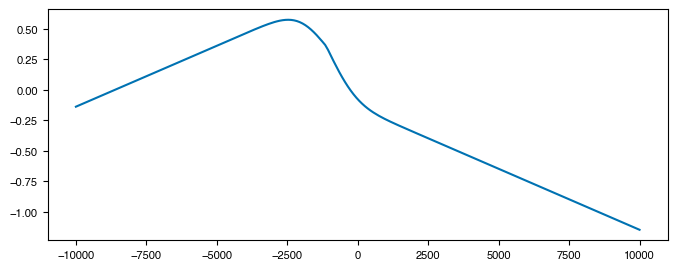

In [147]:
endpts = swath_endpoints(swath_dict['Moron']['x'],swath_dict['Moron']['y'],swath_dict['Moron']['swath_az'], 
                swath_dict['Moron']['swath_length'], swath_dict['Moron']['swath_width'])
xs = np.linspace(endpts[0,0],endpts[1,0],int(swath_dict['Moron']['swath_length']/100))
ys = np.linspace(endpts[0,1],endpts[1,1],int(swath_dict['Moron']['swath_length']/100))
obs = np.column_stack([xs,ys,np.zeros(len(xs))])
dists = np.linspace(-(int(swath_dict['Moron']['swath_length']/2)),
                    int(swath_dict['Moron']['swath_length']/2),int(swath_dict['Moron']['swath_length']/100))
moron_profile = tt.erf_function_twoslope(dists, mdf.par_intercept.values, mdf.par_total_offset.values, 
                         mdf.par_fault_loc.values, mdf.par_shear_width.values, mdf.par_slope1.values, mdf.par_slope2.values)
plt.figure(figsize=(8,3))
plt.plot(dists, moron_profile)

In [148]:
tris, slip = utools.read_usgs_fsp_to_tdcalc('/Volumes/Venezuela/Venezuela2026Doublet/GIS/complete_inversion.fsp', crs_out=crs)

% ---------------------------------- FINITE-SOURCE RUPTURE MODEL ---------------------------------- 

None
%

None
% Event : NEAR COAST OF VENEZUELA 2026-06-24T22:04:33 UTC

None
% EventTAG: 2026-06-24T22:04:33

None
%

None
% Loc  : LAT = 10.436  LON = -68.528  DEP = 20.3

None
% Size : LEN = 60.0 km  WID = 40.0 km  Mw = 7.547693037144929  Mo = 2.6396087280500002e+20 Nm

None
% Mech : STRK = 80.0 DIP = 75.0 RAKE = -175.0  Htop = 2.269384575937394 km

None
% Rupt : HypX = 25.0 km  Hypz = 20.0 km  avTr = 10.85 s  avVr =  2.27 km/s

None
%

None
%  ----------------------------------  inversion-related parameters ---------------------------------- 

None
%

None
% Invs : Nx = 6  Nz = 5 Fmin = 0.01 Hz  Fmax = 0.125 Hz

None
% Invs : Dx = 10 km  Dz = 8 km

None
% Invs : Ntw = 8  Nsg = 2     (# of time-windows,# of fault segments)

None
% Invs : LEN = 3.0 s SHF = 1.5 s    (time-window length and time-shift)

None
% SVF  : AsymmetricCosine    (type of slip-velocity function used)

None
%

Non

In [149]:
# Read the ffm and predict displacement
disp = np.zeros(np.shape(obs))
nu = 0.25
for tri, s in zip(tris, slip):
    disp += tdcalc.TDdispHS(
        obs,
        tri,
        s,
        nu,
    )

ffm_par, ffm_perp = tt.projectParPerp(disp[:,0],disp[:,1],swath_dict['Moron']['fault_az'])

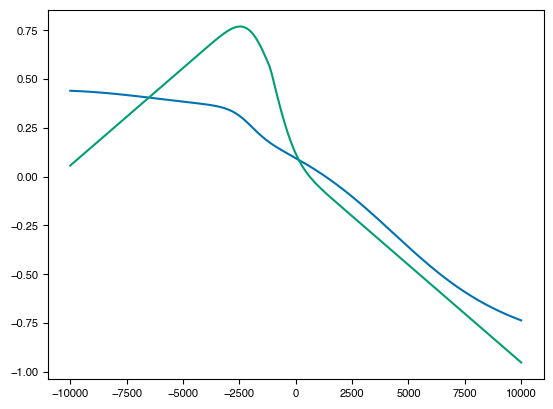

In [150]:
plt.plot(dists,(ffm_par-ffm_par.mean())*5)
plt.plot(dists,moron_profile-moron_profile.mean())

In [ ]:
labels = models.keys()

colors = [
    "#7f7f7f",   # gray
    "#000000",   # black
    "#009E73",   # green
]

fig, ax = plt.subplots(figsize=(7, 3))

for df, label, color in zip(samps_dfs, labels, colors):

    df = df.sort_values("dists")

    ax.scatter(
        df.dists,
        df.par - df.par.mean(),
        s=6,
        color=color,
        alpha=0.6,
        edgecolors="none",
        rasterized=True,   # keeps vector PDFs small
        label=label,
    )
### TDCALC ###
### -------------------- TDCALC -------------------- ###

### -------------------- TDCALC -------------------- ###
for model in models.values():

    disp = np.zeros(len(obs))

    for tri in top_tris:
        disp += tdcalc.TDdispHS(
            obs,
            tri,
            [model["slip_surface"],model["slip_surface"]*0,0],
            nu,
        )[:,0]

    for tri in middle_tris:
        disp += tdcalc.TDdispHS(
            obs,
            tri,
            [model["slip_middle"],model["slip_middle"]*0,0],
            nu,
        )[:,0]

    for tri in bottom_tris:
        disp += tdcalc.TDdispHS(
            obs,
            tri,
            [model["slip_deep"],  model["slip_deep"]*0,0],
            nu,
        )[:,0]

    line, = ax.plot(
        ys,
        disp + model["offset"],
        color=model["color"],
        lw=1.5,
        zorder=20,
    )

    line.set_path_effects([
        pe.Stroke(
            linewidth=3.5,
            foreground=model["outline"],
        ),
        pe.Normal(),
    ])

### -------------------- TDCALC -------------------- ###
### TDCALC ###

ax.set_xlabel("Secondary-Fault Perpendicualar Distance (m)\nNW to SE")
ax.set_ylabel("Parallel Offset (m)")

ax.grid(axis="y", alpha=0.3)
ax.margins(x=0)

ax.legend(
    frameon=False,
    ncol=3,
    loc="lower center",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(
    "/Users/chanagan/Library/CloudStorage/OneDrive-DOI/Desktop/Manuscripts/VenezuelaDoublet2026/Figures/Afterslip/AfterslipProfiles.png",
    dpi=300,
    transparent=True,
)
plt.show()